# Notebook 3: Robuste Verteilungsdiagnostik

**Statistik für Data Science** · Kurs 3,906 · Bachelor Computer Science · HS2026
Universität St. Gallen · Begleitmaterial zur Übung

---

Dieses Notebook führt die Inhalte von **VL03 (Verteilungen visualisieren und diagnostizieren)** in Python aus. Jeder Unterabschnitt beginnt mit einem Problem, holt die passende Theorie aus der Vorlesung, löst das Problem im Code und sagt, was das Ergebnis bedeutet. Am Ende steht jeweils eine Frage für euren eigenen Datensatz.

**Die vier Schritte.** Sie kehren in jedem Unterabschnitt in derselben Reihenfolge wieder:

| Schritt | Was dort steht |
|---|---|
| **Problem.** | Eine konkrete Frage, meist mit einer Zahl aus den Daten |
| **Theorie.** | Was die Vorlesung dazu sagt, mit der Folie: *Vorlesung: Folie «…»* |
| **Code.** | `# Rechnen` berechnet die Statistik, `# Darstellen` zeigt vorher und nachher |
| **Bedeutung.** | Was der Output zeigt und welche Entscheidung daraus folgt |
| **Euer Datensatz.** | Dieselbe Frage für eure eigene Variable |

**Übersicht.** In der Übung zeigen wir die drei mit «im Raum» markierten Unterabschnitte. Danach übertragt ihr sie auf eure eigenen Daten; die Fragen **Euer Datensatz** führen euch dabei.

| | Unterabschnitt | Problem | Übung |
|---|---|---|---|
| **1** | **Histogramm und KDE** | **Wie macht man Form sichtbar, ohne sie zu erfinden?** | |
| 1.1 | Counts oder Dichte? | 405 gegen 6 Tickets im selben Intervall: Was vergleicht ein Counts-Histogramm? | |
| 1.2 | Binregeln: Sturges, Wurzel, Freedman-Diaconis | 11, 30 oder 107 Klassen: Welches Histogramm zeigt die Ticketpreise? | |
| 1.3 | KDE und die Bandbreite | Scott sagt h = 12.77, Silverman h = 3.99: Welche Kurve stimmt? | |
| 1.4 | Binzahl und Bandbreite entscheiden | Überleben die zwei Modi der Flossenlängen jede Bandbreite? | im Raum |
| **2** | **Boxplot und Violinplot** | **Wie vergleicht man Gruppen, ohne zu überinterpretieren?** | |
| 2.1 | Zaunbreite und showfliers | 116 markierte Preise: Regel wechseln oder Punkte ausblenden? | im Raum |
| 2.2 | Notch: Unsicherheitsbereich des Medians | 6 mm Medianunterschied: Zufall der Stichprobe oder echt? | |
| 2.3 | Linear oder Log? | Median 14.45, Maximum 512.33: Warum ist die halbe Grafik leer? | |
| 2.4 | Box oder Violine? | Was verdeckt die eine Box der Biscoe-Flossenlängen? | |
| **3** | **ECDF und QQ-Plot** | **Wie prüft man eine Form gegen eine Referenz?** | |
| 3.1 | ECDF im Gruppenvergleich | Warum liegt die Kurve der grössten Pinguine unten? | |
| 3.2 | QQ-Plot von Hand | Sind die Adelie-Flossen mit einer Normalverteilung verträglich? | |
| 3.3 | Bogen oder S-Kurve? | Beide Reihen haben extreme Werte: Schiefe oder schwere Tails? | |
| 3.4 | Die Diagnose-Routine | Vier Schritte, eine Variable: Welcher Satz kommt ins Log? | im Raum |

**Datensätze.** Der Titanic-Datensatz führt die Analyse aus NB01 und NB02 fort: Der Ticketpreis ist rechtsschief mit schwerem rechtem Tail, das Alter hat fehlende Werte, die Klasse liefert Gruppen. Die Pinguindaten zeigen saubere Gruppenformen: Die bimodale Flossenlänge aus NB02 wird hier zum Testfall für Bandbreite, Violine und ECDF. Simulierte Reihen mit bekannter Wahrheit stehen dort, wo reale Daten eine Eigenschaft nicht kontrolliert liefern. Die zusätzlichen Ausreisserregeln (z-Score, modifizierter z-Score) und die Fallnotiz stehen im Begleitnotebook `NB03_Ausreisserregeln.ipynb`.

**Ein Begriff vorweg: `bw_adjust`.** Die Abkürzung steht für *bandwidth adjust*, die Anpassung der Bandbreite h der Kerndichteschätzung (KDE, ab Abschnitt 1.3). Die seaborn-Dokumentation (Version 0.13.2) definiert den Parameter so: «Factor that multiplicatively scales the value chosen using `bw_method`. Increasing will make the curve smoother.» Er multipliziert also die automatisch gewählte Bandbreite: `bw_adjust=0.5` halbiert sie (feinere Kurve), `bw_adjust=2.0` verdoppelt sie (glattere Kurve). Ohne Angabe gilt `bw_adjust=1.0`, und als `bw_method` nutzt seaborn die Scott-Regel aus der Vorlesung.

## 0. Setup

Es gelten dieselben Konventionen wie in NB01 und NB02: wenige Standardpakete und ein zentraler Seed. Beide Datensätze werden hier einmal geladen. Für ECDF und QQ-Plot brauchen wir kein zusätzliches Paket; die wenigen Schritte werden bewusst ausgeschrieben.

In [102]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

SEED = 42
RNG = np.random.default_rng(SEED)

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (7.5, 4.2)
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

In [103]:
titanic = sns.load_dataset('titanic')
penguins = sns.load_dataset('penguins')

print(f'Titanic:  {titanic.shape[0]} Zeilen, {titanic.shape[1]} Spalten')
print(f'Pinguine: {penguins.shape[0]} Zeilen, {penguins.shape[1]} Spalten')

Titanic:  891 Zeilen, 15 Spalten
Pinguine: 344 Zeilen, 7 Spalten


---

## 1. Histogramm und KDE

*Vorlesung: Abschnitt «Histogramm und KDE». Leitfrage: Wie macht man die Form sichtbar, ohne sie zu erfinden?*

NB02 hat Histogramme benutzt und die Klassenzahl offen gelassen; ihre systematische Wahl, hiess es dort, folgt in VL03. Jetzt ist es so weit: Bins und Bandbreite sind keine Nebensache, sondern steuern, welche Form überhaupt sichtbar wird.

### 1.1 Counts oder Dichte?

**Problem.** Im günstigsten Preisintervall von 0 bis 20 liegen 405 Tickets der dritten Klasse, aber nur 6 der ersten. Sind günstige Tickets in der dritten Klasse also 67-mal typischer? Die dritte Klasse hat 491 Passagiere, die erste 216: Ein Counts-Histogramm vergleicht immer auch die Gruppengrössen mit.

**Theorie.** *Vorlesung: Folie «Histogramm: Grundidee»*

Ein Histogramm teilt die Werte in Klassen fester Breite. Die Höhe kann zweierlei zeigen: die Häufigkeit (Counts) oder die Dichte

$$f_j = \frac{c_j}{n \cdot h}$$

mit $c_j$ Werten in der Klasse, $n$ Werten insgesamt und $h$ Klassenbreite. Beim Dichte-Histogramm ist die Gesamtfläche 1: Nicht die Höhen summieren sich zu 1, sondern die Flächen Höhe mal Breite. Deshalb sind Dichten zwischen Gruppen unterschiedlicher Grösse vergleichbar, Counts nicht. Und nur bei gleicher Klassenbreite lassen sich Balkenhöhen direkt vergleichen; die Dichte selbst ist kein Anteil in Prozent.

**Code.** Für die erste und die dritte Klasse dieselben Klassen der Breite 20: Counts, die Dichte der ersten Klasse von Hand nach der Formel und als Gegenprobe die Flächensumme. Die Grafik legt beide Klassen übereinander, vorher als Counts und nachher als Dichte.

In [104]:
# Rechnen
fare = titanic['fare'].dropna()
preise_first = fare[titanic['class'] == 'First']
preise_third = fare[titanic['class'] == 'Third']

kanten = np.arange(0, 540, 20)      # gemeinsame Klassen der Breite 20, bis über das Maximum
for name, preise in [('First', preise_first), ('Third', preise_third)]:
    counts, _ = np.histogram(preise, bins=kanten)                 # liefert (Anzahlen, Kanten)
    dichte, _ = np.histogram(preise, bins=kanten, density=True)
    dichte_von_hand = counts[0] / (len(preise) * 20)      # f = c / (n·h) für die Klasse [0, 20)
    print(f'{name:5s}  n = {len(preise):3d}   Klasse [0, 20): {counts[0]:3d} Tickets   '
          f'Dichte {dichte[0]:.4f} (von Hand {dichte_von_hand:.4f})   '
          f'Fläche gesamt {(dichte * 20).sum():.3f}')

dichte_third, _ = np.histogram(preise_third, bins=kanten, density=True)
print(f'\nSumme der Dichtehöhen (Third): {dichte_third.sum():.4f}  ->  nicht 1; '
      f'erst Höhe mal Klassenbreite ergibt die Fläche 1')

First  n = 216   Klasse [0, 20):   6 Tickets   Dichte 0.0014 (von Hand 0.0014)   Fläche gesamt 1.000
Third  n = 491   Klasse [0, 20): 405 Tickets   Dichte 0.0412 (von Hand 0.0412)   Fläche gesamt 1.000

Summe der Dichtehöhen (Third): 0.0500  ->  nicht 1; erst Höhe mal Klassenbreite ergibt die Fläche 1


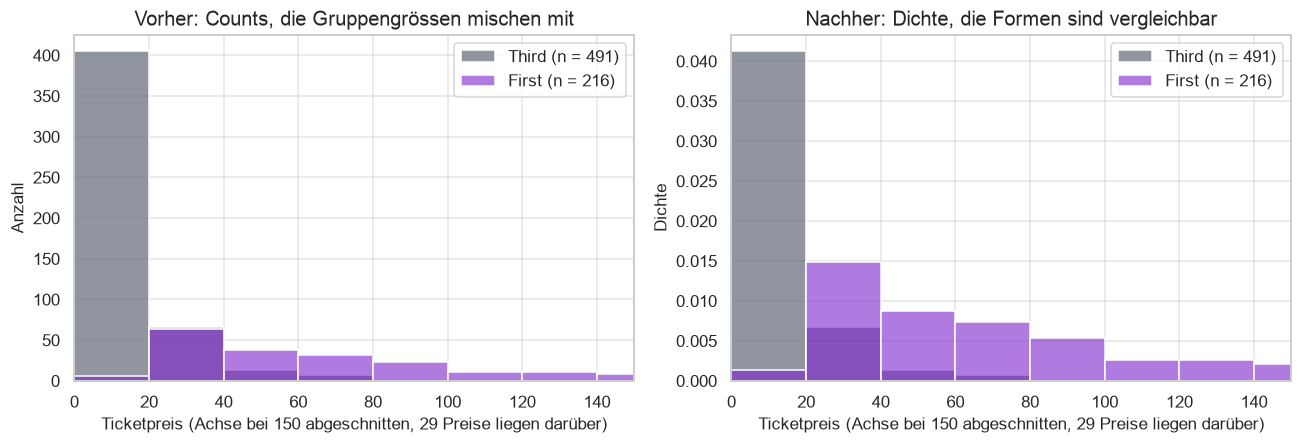

In [105]:
# Darstellen
ueber_150 = (preise_first > 150).sum() + (preise_third > 150).sum()

fig, achsen = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, stat, titel in [
    (achsen[0], 'count', 'Vorher: Counts, die Gruppengrössen mischen mit'),
    (achsen[1], 'density', 'Nachher: Dichte, die Formen sind vergleichbar'),
]:
    sns.histplot(x=preise_third, bins=kanten, stat=stat, color='#6B7280',
                 edgecolor='white', label=f'Third (n = {len(preise_third)})', ax=ax)
    sns.histplot(x=preise_first, bins=kanten, stat=stat, color='#7E22CE',
                 edgecolor='white', alpha=0.6, label=f'First (n = {len(preise_first)})', ax=ax)
    ax.set(title=titel, xlim=(0, 150),
           xlabel=f'Ticketpreis (Achse bei 150 abgeschnitten, {ueber_150} Preise liegen darüber)')
    ax.legend(loc='upper right')
achsen[0].set_ylabel('Anzahl')
achsen[1].set_ylabel('Dichte')
plt.tight_layout()
plt.show()

**Bedeutung.** Die Gegenprobe bestätigt die Formel: 405 von 491 Tickets in der Klasse [0, 20) ergeben die Dichte 0.0412, bei der ersten Klasse sind es 0.0014, und beide Flächensummen sind exakt 1. Links dominieren die 491 Passagiere der dritten Klasse das Bild allein durch ihre Zahl; rechts ist jede Gruppe für sich normiert, und die Formen werden vergleichbar. Counts beantworten «wie viele», Dichte «wie verteilt»: Wer Gruppen vergleicht, vergleicht Dichten und schreibt n je Gruppe an die Grafik.

> **Euer Datensatz.** Vergleicht ihr Gruppen unterschiedlicher Grösse? Zeichnet ihr dann Counts oder Dichte, und steht n je Gruppe an der Grafik?

### 1.2 Binregeln: Sturges, Wurzel, Freedman-Diaconis

**Problem.** NB02 hat die Ticketpreise mit 30 Klassen gezeichnet, ohne die Zahl zu begründen; das ist genau die Wurzelregel. Sturges schlägt für dieselben 891 Preise 11 Klassen vor, Freedman-Diaconis 107. Drei Regeln, drei Bilder.

**Theorie.** *Vorlesung: Folien «Binwahl: Regeln und Formeln», «Histogramme lesen»*

Sturges $B = \lceil \log_2 n + 1 \rceil$ und die Wurzelregel $B = \lceil \sqrt{n} \rceil$ liefern eine Klassen**zahl**, Freedman-Diaconis eine Klassen**breite**

$$h = \frac{2 \cdot IQR}{\sqrt[3]{n}}.$$

Sturges ist konservativ und passt zu normalnahen Daten; FD nutzt den robusten IQR und ist deshalb der Praxis-Default, besonders bei Schiefe. Gelesen wird ein Histogramm immer auf dieselben vier Dinge: Schiefe, Moden, Lücken und Tails.

**Code.** Alle drei Formeln von Hand, dann die Gegenprobe mit NumPy. Die Grafik zeigt dieselben Ticketpreise mit 11, 30 und 107 Klassen.

In [106]:
# Rechnen
n = len(fare)
q1, q3 = fare.quantile([0.25, 0.75])      # zwei Quantile auf einmal, entpackt in zwei Namen
iqr = q3 - q1
spannweite = fare.max() - fare.min()

bins_sturges = int(np.ceil(np.log2(n) + 1))
bins_wurzel = int(np.ceil(np.sqrt(n)))
h_fd = 2 * iqr / np.cbrt(n)
bins_fd = int(np.ceil(spannweite / h_fd))

print(f'n = {n}, IQR = {iqr:.2f}, Spannweite = {spannweite:.2f}')
print(f'Sturges:           {bins_sturges:3d} Klassen   (ergibt Breite {spannweite / bins_sturges:.2f})')
print(f'Wurzelregel:       {bins_wurzel:3d} Klassen   (ergibt Breite {spannweite / bins_wurzel:.2f})')
print(f'Freedman-Diaconis: Klassenbreite h = {h_fd:.2f}, '
      f'Spannweite / h = {spannweite / h_fd:.2f}, aufgerundet {bins_fd} Klassen')
print()
for regel in ['sturges', 'sqrt', 'fd']:
    kanten_regel = np.histogram_bin_edges(fare, bins=regel)
    print(f"Gegenprobe np.histogram_bin_edges(bins='{regel}'): {len(kanten_regel) - 1} Klassen, "
          f'Breite {kanten_regel[1] - kanten_regel[0]:.2f}')

n = 891, IQR = 23.09, Spannweite = 512.33
Sturges:            11 Klassen   (ergibt Breite 46.58)
Wurzelregel:        30 Klassen   (ergibt Breite 17.08)
Freedman-Diaconis: Klassenbreite h = 4.80, Spannweite / h = 106.76, aufgerundet 107 Klassen

Gegenprobe np.histogram_bin_edges(bins='sturges'): 11 Klassen, Breite 46.58
Gegenprobe np.histogram_bin_edges(bins='sqrt'): 30 Klassen, Breite 17.08
Gegenprobe np.histogram_bin_edges(bins='fd'): 107 Klassen, Breite 4.79


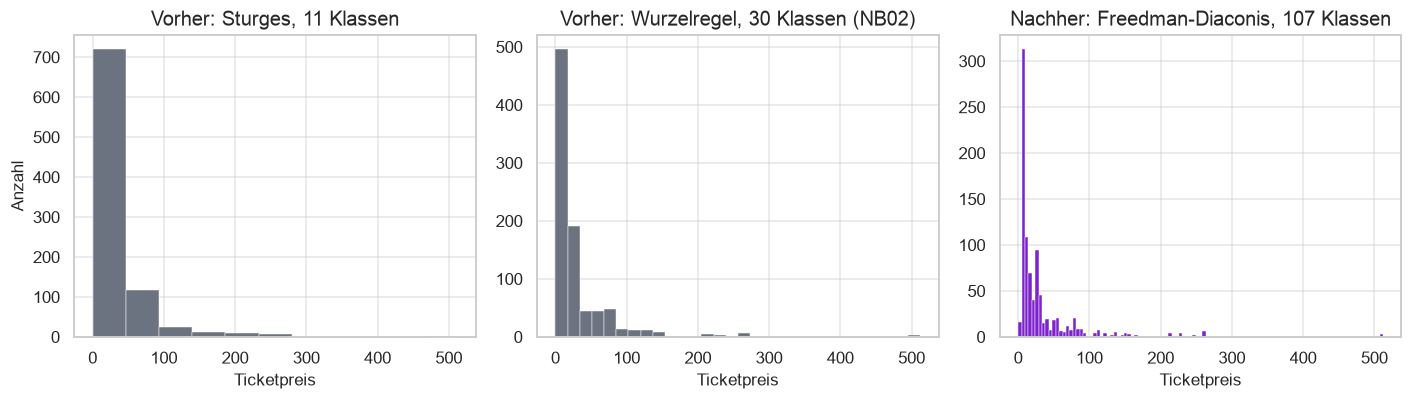

In [107]:
# Darstellen
fig, achsen = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, bins, titel, farbe in zip(
    achsen,
    [bins_sturges, bins_wurzel, bins_fd],
    [f'Vorher: Sturges, {bins_sturges} Klassen',
     f'Vorher: Wurzelregel, {bins_wurzel} Klassen (NB02)',
     f'Nachher: Freedman-Diaconis, {bins_fd} Klassen'],
    ['#6B7280', '#6B7280', '#7E22CE'],
):
    ax.hist(fare, bins=bins, color=farbe, edgecolor='white', linewidth=0.3)
    ax.set(title=titel, xlabel='Ticketpreis')
achsen[0].set_ylabel('Anzahl')
plt.tight_layout()
plt.show()

**Bedeutung.** Dreimal dieselben 891 Werte, drei Geschichten. Mit 11 Klassen (Breite 46.58) ist alles bis 46 ein einziger Block; die Struktur der günstigen Tickets ist weggemittelt. Mit 107 schmalen Klassen (Breite 4.79) wird sichtbar, dass die häufigsten Preise zwischen 5 und 10 liegen und dass zwischen den Preisstufen Lücken bleiben. (Die Gegenprobe zeigt 4.79 statt 4.80: Das ist die realisierte Breite Spannweite/107, etwas kleiner als h, weil die Klassenzahl aufgerundet wurde.) Einzelne kleine Zacken in diesem feinen Bild sind allerdings parameterabhängig und deshalb kein belastbarer Modus. Der Merksatz der Vorlesung: Sturges für Normalnähe, FD für Schiefe. Und weil die Klassenzahl die Aussage steuert, gehört diese Entscheidung dokumentiert.

> **Euer Datensatz.** Rechnet Sturges und Freedman-Diaconis für eure Variable. Wie weit liegen die Klassenzahlen auseinander, und welche Regel passt zur Form eurer Verteilung?

### 1.3 KDE und die Bandbreite

**Problem.** `sns.kdeplot(fare)` zeichnet kommentarlos eine glatte Kurve. Hinter ihr steckt eine Wahl: Die Scott-Regel ergibt für die Ticketpreise die Bandbreite h = 12.77, die Silverman-Regel h = 3.99, mehr als Faktor drei dazwischen. Welche Kurve stimmt?

**Theorie.** *Vorlesung: Folien «KDE (Kerndichteschätzung): Idee der Glättung», «Bandbreite wählen»*

Die Kerndichteschätzung legt über jeden Datenpunkt eine kleine Gauss-Glocke und summiert sie:

$$\hat f_h(x) = \frac{1}{n\,h} \sum_{i=1}^{n} K\!\left(\frac{x - x_i}{h}\right)$$

Der Term $(x - x_i)/h$ ist der Abstand zum Datenpunkt in Einheiten von h. Die KDE ist binfrei, aber nicht parameterfrei: Die Bandbreite h steuert die Glättung. Zwei Regeln aus der Vorlesung: Scott $h = \sigma / \sqrt[5]{n}$, gut bei normalnahen Daten, und Silverman $h = 0.9 \cdot \min(\sigma,\; IQR/1.34) / \sqrt[5]{n}$, robuster bei Schiefe.

**Code.** Zuerst die Formel einmal von Hand an acht kleinen Latenzwerten; die erste Grafik zeigt diese acht Werte mit ihren Glocken und der Summe. Dann beide Bandbreiten-Regeln für die Ticketpreise; die zweite Grafik zeigt die KDE mit dem seaborn-Default (Scott) und mit der Silverman-Bandbreite, beide über dem FD-Histogramm als Dichte.

In [108]:
# Rechnen
# Die Formel einmal von Hand: 8 Latenzmessungen, Bandbreite h = 2, ausgewertet an der Stelle x = 10
latenz_klein = np.array([5, 7, 8, 9, 11, 12, 15, 22])
h_demo = 2
x_stelle = 10

z = (x_stelle - latenz_klein) / h_demo                 # Abstand in Einheiten von h
glocken = np.exp(-0.5 * z ** 2) / np.sqrt(2 * np.pi)   # Gauss-Kern K(z) je Datenpunkt
dichte_an_der_stelle = glocken.sum() / (len(latenz_klein) * h_demo)

print('Beitrag jeder Glocke an der Stelle x = 10:', np.round(glocken, 3))
print(f'Summe / (n·h) = {glocken.sum():.3f} / {len(latenz_klein) * h_demo} = {dichte_an_der_stelle:.4f}')
print('Die KDE ist nichts anderes als diese Summe, an jeder Stelle x ausgewertet.')

Beitrag jeder Glocke an der Stelle x = 10: [0.018 0.13  0.242 0.352 0.352 0.242 0.018 0.   ]
Summe / (n·h) = 1.353 / 16 = 0.0845
Die KDE ist nichts anderes als diese Summe, an jeder Stelle x ausgewertet.


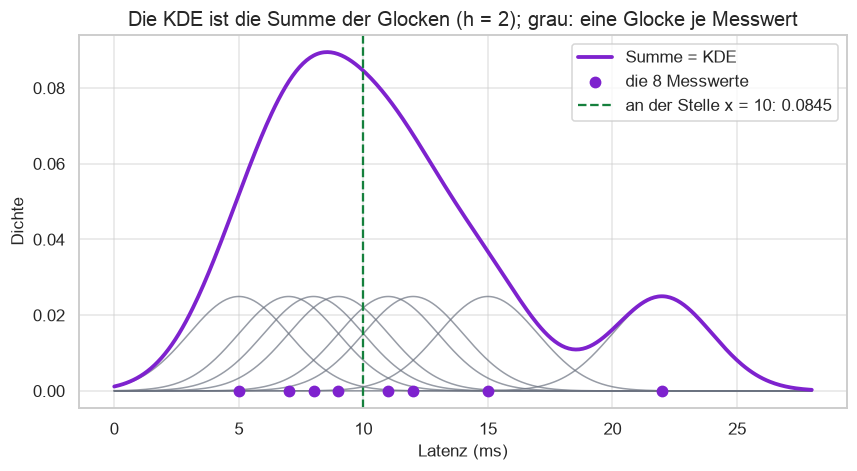

In [109]:
# Darstellen
gitter_demo = np.linspace(0, 28, 400)
summe = np.zeros(len(gitter_demo))

fig, ax = plt.subplots(figsize=(9, 4.4))
for wert in latenz_klein:
    # dieselben Zeilen wie oben, nur an jeder Gitterstelle statt nur bei x = 10
    z_gitter = (gitter_demo - wert) / h_demo
    glocke = np.exp(-0.5 * z_gitter ** 2) / np.sqrt(2 * np.pi) / (len(latenz_klein) * h_demo)
    summe = summe + glocke
    ax.plot(gitter_demo, glocke, color='#6B7280', linewidth=1, alpha=0.7)
ax.plot(gitter_demo, summe, color='#7E22CE', linewidth=2.5, label='Summe = KDE')
ax.scatter(latenz_klein, np.zeros(len(latenz_klein)), s=45, color='#7E22CE', zorder=3,
           label='die 8 Messwerte')
ax.axvline(x_stelle, color='#15803D', linestyle='--', linewidth=1.5,
           label=f'an der Stelle x = 10: {dichte_an_der_stelle:.4f}')
ax.set(title='Die KDE ist die Summe der Glocken (h = 2); grau: eine Glocke je Messwert',
       xlabel='Latenz (ms)', ylabel='Dichte')
ax.legend(loc='upper right')
plt.show()

In [110]:
# Rechnen
sd = fare.std(ddof=1)

h_scott = sd / n ** 0.2
h_silverman = 0.9 * min(sd, iqr / 1.34) / n ** 0.2

print(f'SD = {sd:.2f}, IQR/1.34 = {iqr / 1.34:.2f}  ->  Silverman nimmt den kleineren der beiden Werte')
print(f'Scott:     h = {h_scott:.2f}')
print(f'Silverman: h = {h_silverman:.2f}')
print(f'Verhältnis Silverman/Scott: {h_silverman / h_scott:.2f}  (als bw_adjust nutzbar)')

SD = 49.69, IQR/1.34 = 17.23  ->  Silverman nimmt den kleineren der beiden Werte
Scott:     h = 12.77
Silverman: h = 3.99
Verhältnis Silverman/Scott: 0.31  (als bw_adjust nutzbar)


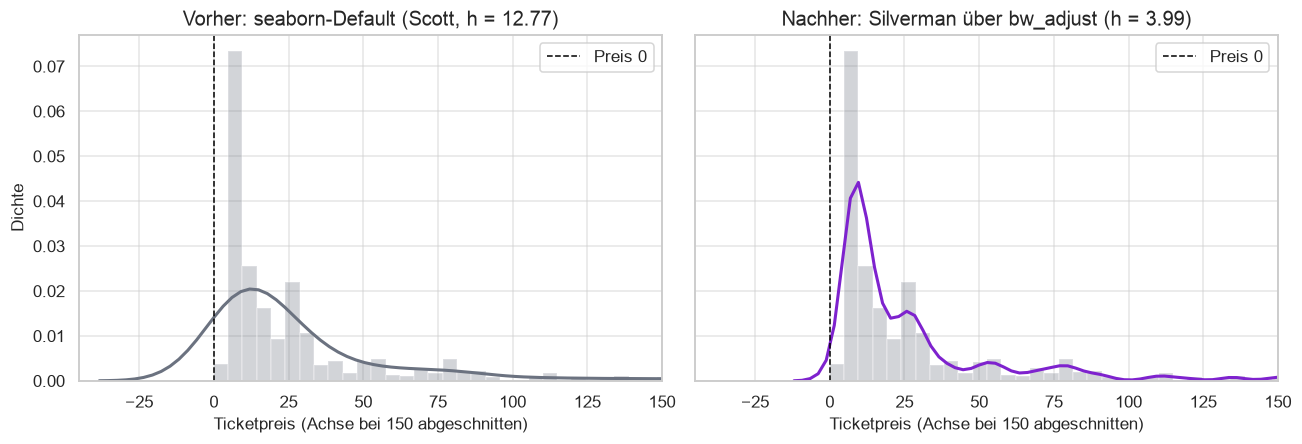

In [111]:
# Darstellen
kanten_fd = np.histogram_bin_edges(fare, bins='fd')

fig, achsen = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, bw, titel, farbe in zip(
    achsen,
    [1.0, h_silverman / h_scott],
    [f'Vorher: seaborn-Default (Scott, h = {h_scott:.2f})',
     f'Nachher: Silverman über bw_adjust (h = {h_silverman:.2f})'],
    ['#6B7280', '#7E22CE'],
):
    ax.hist(fare, bins=kanten_fd, density=True, color='#6B7280', alpha=0.3, edgecolor='white')
    sns.kdeplot(fare, bw_adjust=bw, color=farbe, linewidth=2, ax=ax)
    ax.axvline(0, color='black', linestyle='--', linewidth=1, label='Preis 0')
    ax.set(title=titel, xlim=(-45, 150), xlabel='Ticketpreis (Achse bei 150 abgeschnitten)')
    ax.legend(loc='upper right')
achsen[0].set_ylabel('Dichte')
plt.tight_layout()
plt.show()

**Bedeutung.** Scott unterstellt Normalnähe und nimmt die SD, die der schwere rechte Tail auf 49.69 aufbläht; Silverman greift auf den robusten IQR zurück (17.23 nach der Division durch 1.34) und bleibt bei h = 3.99. Links überglättet die Scott-Kurve die Spitze und legt sichtbar Dichte links vom Preis 0, obwohl es keine negativen Preise gibt; rechts bleibt die Spitze stehen und der Überhang ist deutlich kleiner.

**Hinweis zur Bibliothek:** `bw_method='silverman'` in seaborn und scipy rechnet nicht die Silverman-Formel der Folie, sondern eine Variante ohne den min-Term; für die Ticketpreise ergäbe sie h = 13.5, fast wie Scott. Deshalb rechnet das Notebook die Folienformel von Hand und setzt sie als Faktor über `bw_adjust = 3.99 / 12.77 = 0.31`. Der seaborn-Default entspricht der Scott-Formel der Folie.

> **Euer Datensatz.** Wie weit liegen Scott und Silverman bei eurer Variable auseinander? Wenn sie sich stark unterscheiden: Was sagt das über die Form eurer Verteilung?

### 1.4 Binzahl und Bandbreite entscheiden

**Problem.** NB02 hat gezeigt, dass die Flossenlängen der Pinguine bimodal sind, weil Arten gemischt sind. Mit `bw_adjust=2.0` zeichnet seaborn dieselben 342 Werte als glatte Kurve mit genau einem Modus. Welche Einstellung dürft ihr berichten?

**Theorie.** *Vorlesung: Folien «Histogramm oder KDE?», «Beispiel Penguins flipper_length», «Mini-Aufgabe: Binzahl und Bandbreite»*

Histogramm und KDE haben komplementäre Stärken: Das Histogramm zeigt Häufigkeiten direkt und Lücken hart, die KDE eine glatte Form; beste Praxis ist das Overlay aus beiden. `bw_adjust` skaliert die Bandbreite: unter 1 feiner, über 1 glatter. Die Mini-Aufgabe der Vorlesung prüft {0.5, 1.0, 2.0}: Was nur bei einer Einstellung erscheint, ist verdächtig; echte Struktur übersteht die feinen Bandbreiten und verschwindet erst, wenn h zu gross wird.

**Code.** Erst die Binregeln für die Flossenlängen, dann werden die Moden für drei Bandbreiten gezählt statt behauptet: die KDE als Glockensumme auf einem Gitter, lokale Maxima zählen. Die Grafik zeigt die überglättete Kurve und das Overlay.

In [112]:
# Rechnen
flipper = penguins['flipper_length_mm'].dropna()
n_flipper = len(flipper)
q1_f, q3_f = flipper.quantile([0.25, 0.75])
h_fd_flipper = 2 * (q3_f - q1_f) / np.cbrt(n_flipper)
spannweite_flipper = flipper.max() - flipper.min()
bins_fd_flipper = int(np.ceil(spannweite_flipper / h_fd_flipper))

print(f'n = {n_flipper}, Spannweite = {spannweite_flipper:.0f} mm')
print(f'Sturges:           {int(np.ceil(np.log2(n_flipper) + 1))} Klassen')
print(f'Wurzelregel:       {int(np.ceil(np.sqrt(n_flipper)))} Klassen')
print(f'Freedman-Diaconis: Klassenbreite h = {h_fd_flipper:.2f} mm, '
      f'Spannweite / h = {spannweite_flipper / h_fd_flipper:.2f}, '
      f'aufgerundet {bins_fd_flipper} Klassen')
print('Verglichen mit dem Ticketpreis (11, 30, 107) liegen die Regeln hier nah beieinander.')

n = 342, Spannweite = 59 mm
Sturges:           10 Klassen
Wurzelregel:       19 Klassen
Freedman-Diaconis: Klassenbreite h = 6.58 mm, Spannweite / h = 8.97, aufgerundet 9 Klassen
Verglichen mit dem Ticketpreis (11, 30, 107) liegen die Regeln hier nah beieinander.


In [113]:
# Rechnen
# Moden zählen statt behaupten: die KDE aus 1.3 auf einem Gitter auswerten, lokale Maxima zählen
h_scott_flipper = flipper.std(ddof=1) / n_flipper ** 0.2
gitter = np.linspace(flipper.min() - 10, flipper.max() + 10, 500)
werte = flipper.to_numpy()

zeilen = []
for faktor in [0.5, 1.0, 2.0]:
    h = faktor * h_scott_flipper

    # KDE an jeder Gitterstelle, mit denselben Zeilen wie in 1.3
    dichte = np.zeros(len(gitter))
    for i in range(len(gitter)):
        z_gitter = (gitter[i] - werte) / h
        glocken_gitter = np.exp(-0.5 * z_gitter ** 2) / np.sqrt(2 * np.pi)
        dichte[i] = glocken_gitter.sum() / (len(werte) * h)

    # lokales Maximum: höher als der linke und der rechte Nachbar
    moden = []
    for i in range(1, len(gitter) - 1):
        if dichte[i] > dichte[i - 1] and dichte[i] > dichte[i + 1]:
            moden.append(round(gitter[i]))

    zeilen.append({'bw_adjust': faktor, 'h (mm)': round(h, 2),
                   'Moden': len(moden), 'Lage der Moden (mm)': moden})

pd.DataFrame(zeilen)

,bw_adjust,h (mm),Moden,Lage der Moden (mm)
0,0.5,2.19,3,"[191, 215, 229]"
1,1.0,4.38,2,"[192, 214]"
2,2.0,8.76,1,[193]


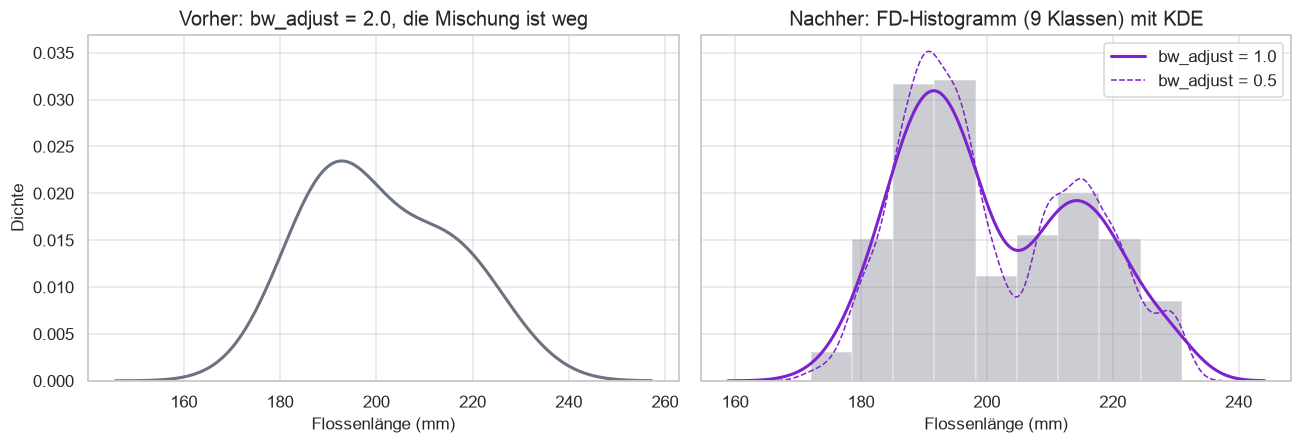

In [114]:
# Darstellen
kanten_flipper = np.histogram_bin_edges(flipper, bins='fd')

fig, achsen = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)

sns.kdeplot(flipper, bw_adjust=2.0, color='#6B7280', linewidth=2, ax=achsen[0])
achsen[0].set(title='Vorher: bw_adjust = 2.0, die Mischung ist weg',
              xlabel='Flossenlänge (mm)', ylabel='Dichte')

achsen[1].hist(flipper, bins=kanten_flipper, density=True, color='#6B7280', alpha=0.35,
               edgecolor='white')
sns.kdeplot(flipper, bw_adjust=1.0, color='#7E22CE', linewidth=2,
            label='bw_adjust = 1.0', ax=achsen[1])
sns.kdeplot(flipper, bw_adjust=0.5, color='#7E22CE', linewidth=1, linestyle='--',
            label='bw_adjust = 0.5', ax=achsen[1])
achsen[1].set(title=f'Nachher: FD-Histogramm ({bins_fd_flipper} Klassen) mit KDE',
              xlabel='Flossenlänge (mm)')
achsen[1].legend(loc='upper right')
plt.tight_layout()
plt.show()

**Bedeutung.** Die Tabelle macht die Entscheidung nachprüfbar: Zwei Modi erscheinen bei 0.5 und bei 1.0 (bei 1.0 liegen sie bei 192 und 214 mm); der dritte Zacken um 229 mm existiert nur bei 0.5 und ist Rauschen. Bei 2.0 ist auch die echte Struktur weggeglättet, das linke Bild zeigt die Folge. Die Logik dahinter: Rauschen erscheint nur bei der feinsten Einstellung, echte Struktur übersteht die feinen Bandbreiten und verschwindet erst beim Überglätten. Der Satz für das Entscheidungs-Log lautet deshalb: «Wir berichten das FD-Histogramm (9 Klassen) mit KDE bw_adjust=1.0; die zwei Modi erscheinen bei 0.5 und 1.0 und verschwinden erst beim Überglätten mit 2.0.»

> **Euer Datensatz.** Zeichnet euer Overlay mit `bw_adjust` 0.5, 1.0 und 2.0. Welche Struktur bleibt über alle drei stabil, und welchen Satz schreibt ihr ins Log?

> **Take-Home Histogramm und KDE**
>
> 1. **Counts** zählen, **Dichte** vergleicht: Fläche 1, n je Gruppe nennen.
> 2. **Binwahl** steuert die Aussage: Sturges für Normalnähe, FD als robuster Default bei Schiefe.
> 3. **KDE** ist eine Summe von Glocken: binfrei, aber nicht parameterfrei; h robust wählen (Silverman bei Schiefe).
> 4. **Stabilität prüfen:** `bw_adjust` in {0.5, 1.0, 2.0}: Rauschen erscheint nur bei der feinsten Einstellung, echte Struktur verschwindet erst beim Überglätten.
> 5. **Beste Praxis:** Overlay aus Histogramm und KDE.
>
> Bins und Bandbreite gehören zur Aussage und damit in den Bericht.

---

## 2. Boxplot und Violinplot

*Vorlesung: Abschnitt «Boxplot und Violinplot». Leitfrage: Wie vergleicht man Gruppen robust, ohne zu überinterpretieren?*

Die Anatomie des Boxplots und die Tukey-Zäune kennt ihr aus NB02: Die 1.5·IQR-Regel markiert dort 116 von 891 Ticketpreisen. Dieses Kapitel wiederholt das nicht, sondern dreht an den Stellschrauben des Plots: Whisker-Regel, Kerben, Skala, und wann die Box durch eine Violine ergänzt werden muss. Weitere Markierungsregeln und der dokumentierte Umgang mit Kandidaten (Fallnotiz) stehen im Begleitnotebook `NB03_Ausreisserregeln.ipynb`.

### 2.1 Zaunbreite und showfliers

**Problem.** Die 1.5·IQR-Regel markiert 116 von 891 Ticketpreisen. Wüchse der Datensatz auf 100 000 Zeilen mit derselben Form, wären es Tausende von Punkten am oberen Rand. Regel wechseln (`whis`), Punkte ausblenden (`showfliers=False`), oder beides lassen?

**Theorie.** *Vorlesung: Folien «Boxplot: Anatomie», «Whisker?», «Fallen beim Lesen»*

Zur Erinnerung: Die Zäune liegen bei $Q_1 - 1.5 \cdot IQR$ und $Q_3 + 1.5 \cdot IQR$, die Whisker enden am letzten **beobachteten** Wert innerhalb der Zäune, nicht bei Minimum und Maximum, und Punkte ausserhalb sind Kandidaten, kein Urteil. Neu sind zwei Stellschrauben. `whis=[5, 95]` setzt die Whisker auf Perzentile: Dann liegen per Definition immer rund 10 Prozent der Werte aussen, das sind Verteilungsenden, keine Kandidaten. Und selbst bei perfekt normalverteilten Daten markiert die Tukey-Regel rund 0.7 Prozent der Punkte.

**Code.** Beide Regeln auf allen Ticketpreisen zusammen; die erste Grafik zeigt die Boxplots je Klasse mit den drei whis-Einstellungen. Danach die 0.7-Prozent-Behauptung als Simulation mit bekannter Wahrheit, samt Bild der simulierten Werte.

In [115]:
# Rechnen
q1, q3 = fare.quantile([0.25, 0.75])
iqr = q3 - q1
unterer_zaun = q1 - 1.5 * iqr
oberer_zaun = q3 + 1.5 * iqr
tukey_anzahl = ((fare < unterer_zaun) | (fare > oberer_zaun)).sum()

p5, p95 = fare.quantile([0.05, 0.95])
perzentil_aussen = ((fare < p5) | (fare > p95)).sum()

print(f'Tukey (whis=1.5):          Zäune {unterer_zaun:.2f} bis {oberer_zaun:.2f}, '
      f'markiert {tukey_anzahl} von {len(fare)} ({tukey_anzahl / len(fare):.1%})')
print(f'Perzentile (whis=[5, 95]): P5 = {p5:.2f}, P95 = {p95:.2f}, '
      f'aussen {perzentil_aussen} von {len(fare)} ({perzentil_aussen / len(fare):.1%})')

Tukey (whis=1.5):          Zäune -26.72 bis 65.63, markiert 116 von 891 (13.0%)
Perzentile (whis=[5, 95]): P5 = 7.22, P95 = 112.08, aussen 88 von 891 (9.9%)


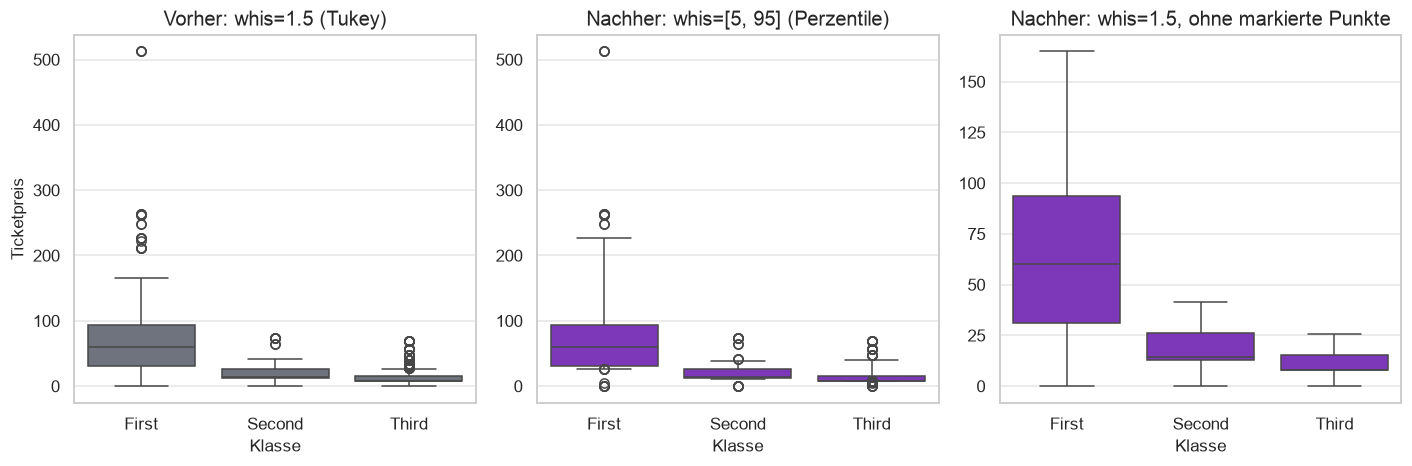

In [116]:
# Darstellen
fig, achsen = plt.subplots(1, 3, figsize=(13, 4.4))

sns.boxplot(data=titanic, x='class', y='fare', whis=1.5, color='#6B7280', ax=achsen[0])
achsen[0].set(title='Vorher: whis=1.5 (Tukey)', xlabel='Klasse', ylabel='Ticketpreis')

sns.boxplot(data=titanic, x='class', y='fare', whis=[5, 95], color='#7E22CE', ax=achsen[1])
achsen[1].set(title='Nachher: whis=[5, 95] (Perzentile)', xlabel='Klasse', ylabel='')

sns.boxplot(data=titanic, x='class', y='fare', whis=1.5, showfliers=False, color='#7E22CE',
            ax=achsen[2])
achsen[2].set(title='Nachher: whis=1.5, ohne markierte Punkte', xlabel='Klasse', ylabel='')

plt.tight_layout()
plt.show()

In [117]:
# Rechnen
# Die 0.7-Prozent-Behauptung der Folie mit bekannter Wahrheit prüfen
rng_normal = np.random.default_rng(SEED)
normalwerte = rng_normal.standard_normal(100_000)
q1_n, q3_n = np.quantile(normalwerte, [0.25, 0.75])
iqr_n = q3_n - q1_n
markiert_normal = ((normalwerte < q1_n - 1.5 * iqr_n) | (normalwerte > q3_n + 1.5 * iqr_n)).sum()

print('100 000 normalverteilte Werte, kein einziger davon ein Fehler:')
print(f'Die Tukey-Regel markiert {markiert_normal} Punkte ({markiert_normal / 100_000:.2%})')

100 000 normalverteilte Werte, kein einziger davon ein Fehler:
Die Tukey-Regel markiert 740 Punkte (0.74%)


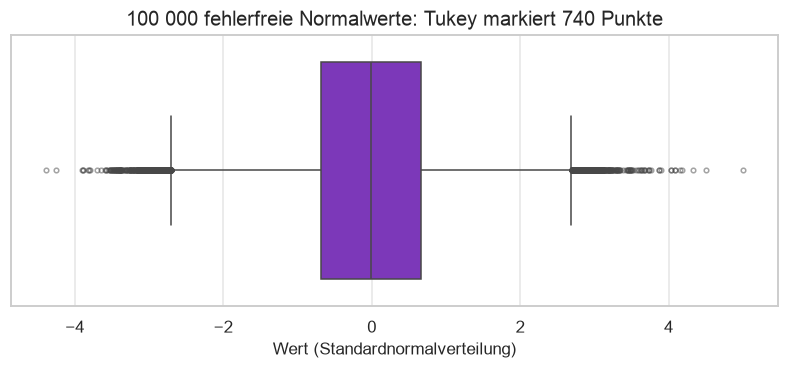

In [118]:
# Darstellen
fig, ax = plt.subplots(figsize=(9, 3.2))
sns.boxplot(x=normalwerte, whis=1.5, color='#7E22CE', ax=ax,
            flierprops=dict(markersize=3, alpha=0.5))
ax.set(title=f'100 000 fehlerfreie Normalwerte: Tukey markiert {markiert_normal} Punkte',
       xlabel='Wert (Standardnormalverteilung)', yticks=[])
plt.show()

**Bedeutung.** Drei Bilder derselben Daten, drei Botschaften. `whis` ändert, wer markiert wird: Über alle Passagiere zusammen sind es 116 Kandidaten unter Tukey, und unter [5, 95] liegen per Konstruktion immer rund 10 Prozent aussen (88 Werte). Die Boxplots je Klasse rechnen ihre Grenzen dagegen pro Gruppe und zeigen deshalb andere Punktmengen (Tukey je Klasse: zusammen 79, NB02 2.4). Die Simulation zeigt die zweite Falle: Selbst 100 000 fehlerfreie Normalwerte liefern 740 markierte Punkte, im letzten Bild als die gewöhnlichen Punktreihen an beiden Enden jenseits der Whisker sichtbar. Markiert heisst also nie automatisch fehlerhaft. Im dritten Panel des Klassenvergleichs schrumpft die Achse auf die Boxen: `showfliers=False` ist zulässig, wenn die Punkte die Skala sprengen, aber nur mit Hinweis in der Beschriftung und der Zahl der ausgeblendeten Punkte im Text. Welche Regel auch gilt: Sie gehört mit Begründung ins Entscheidungs-Log.

> **Euer Datensatz.** Welche Whisker-Regel passt zu eurer Frage, und was macht ihr mit den markierten Punkten: zeigen, ausblenden mit Hinweis, oder getrennt untersuchen? Haltet die Wahl mit Begründung im Log fest.

### 2.2 Notch: Unsicherheitsbereich des Medians

**Problem.** Die Flossen der Adelie haben den Median 190.0 mm (n = 151), die der Chinstrap 196.0 mm (n = 68). Auf der Titanic liegt der Altersmedian der Männer bei 29.0 Jahren (n = 453), der der Frauen bei 27.0 (n = 261). Zwei Medianunterschiede, 6 mm und 2 Jahre: Welcher trägt?

**Theorie.** *Vorlesung: Folien «Notch?», «Gruppenvergleich: Boxplot»*

Zöge man morgen eine neue Stichprobe, läge der Median etwas anders. Die Kerbe (Notch) um den Median zeigt diesen Unsicherheitsbereich. Überlappen die Kerben zweier Gruppen nicht, ist das ein starker visueller Hinweis auf einen echten Lageunterschied; überlappen sie, sollte man keinen behaupten. Das ist eine Faustregel, kein Test, und bei kleinem n unzuverlässig: Die Kerbe kann dann sogar über die Box hinausklappen. Wie man diesen Bereich präzise definiert und berechnet, kommt in Woche 06/07.

**Code.** Nur Mediane und n je Gruppe; die Kerben zeichnet der Plot. Die erste Grafik zeigt die Flossen ohne und mit Kerbe, die zweite das Alter nach Geschlecht als Gegenbeispiel.

In [119]:
# Rechnen
print(penguins.groupby('species')['flipper_length_mm'].agg(['count', 'median']))
print()
print(titanic.groupby('sex')['age'].agg(['count', 'median']))

           count  median
species                 
Adelie       151   190.0
Chinstrap     68   196.0
Gentoo       123   216.0

        count  median
sex                  
female    261    27.0
male      453    29.0


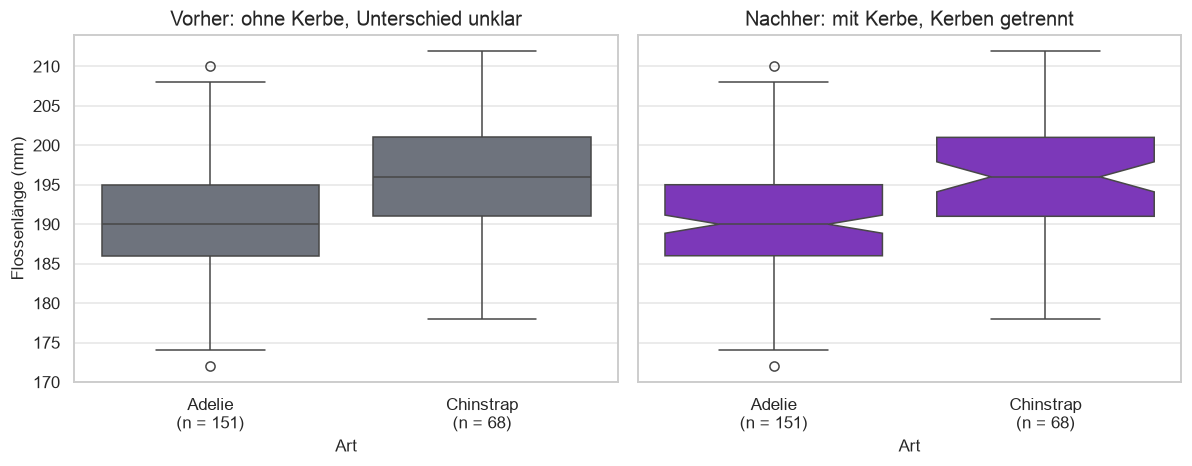

In [120]:
# Darstellen
zwei_arten = penguins[penguins['species'].isin(['Adelie', 'Chinstrap'])]
n_je_art = zwei_arten.groupby('species')['flipper_length_mm'].count()
beschriftung_arten = [f'Adelie\n(n = {n_je_art["Adelie"]})',
                      f'Chinstrap\n(n = {n_je_art["Chinstrap"]})']

fig, achsen = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, kerbe, titel, farbe in zip(
    achsen, [False, True],
    ['Vorher: ohne Kerbe, Unterschied unklar', 'Nachher: mit Kerbe, Kerben getrennt'],
    ['#6B7280', '#7E22CE'],
):
    sns.boxplot(data=zwei_arten, x='species', y='flipper_length_mm',
                order=['Adelie', 'Chinstrap'], color=farbe, notch=kerbe, ax=ax)
    ax.set(title=titel, xlabel='Art', ylabel='')
    ax.set_xticks(range(2), beschriftung_arten)
achsen[0].set_ylabel('Flossenlänge (mm)')
plt.tight_layout()
plt.show()

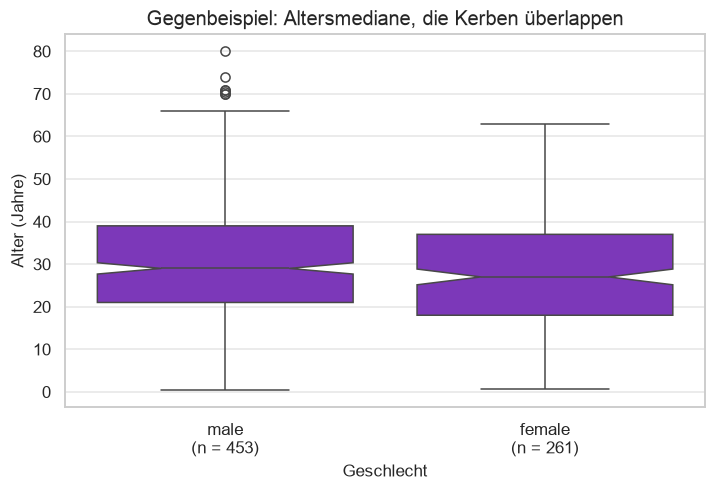

In [121]:
# Darstellen
n_je_geschlecht = titanic.groupby('sex')['age'].count()

fig, ax = plt.subplots(figsize=(7.5, 4.4))
sns.boxplot(data=titanic, x='sex', y='age', order=['male', 'female'], color='#7E22CE',
            notch=True, ax=ax)
ax.set(title='Gegenbeispiel: Altersmediane, die Kerben überlappen', xlabel='Geschlecht',
       ylabel='Alter (Jahre)')
ax.set_xticks(range(2), [f'male\n(n = {n_je_geschlecht["male"]})',
                         f'female\n(n = {n_je_geschlecht["female"]})'])
plt.show()

**Bedeutung.** Der 6-mm-Unterschied der Flossen trägt: Die Kerben von Adelie und Chinstrap berühren sich nicht. Der 2-Jahre-Unterschied beim Alter ist dagegen nicht belastbar: Die Kerben überlappen deutlich, obwohl der Medianabstand im Plot ähnlich gross wirken kann. Eine Falle aus der Vorlesung gleich mit: Der Strich in der Box ist der Median, nicht der Mittelwert. Was «Unsicherheitsbereich» genau heisst, beantwortet die Vorlesung in Woche 06/07; bis dahin gilt die Kerbe als visuelle Faustregel.

> **Euer Datensatz.** Zeichnet euren wichtigsten Gruppenvergleich mit `notch=True`. Überlappen die Kerben, und welchen Satz dürft ihr dann (nicht) schreiben?

### 2.3 Linear oder Log?

**Problem.** Der Ticketpreis hat den Median 14.45 und das Maximum 512.33. Auf der linearen Achse presst der teuerste Passagier alle drei Klassen-Boxen in das untere Sechstel der Grafik. Dazu kommen 15 Tickets, die exakt 0 kosten. Wie zeigt man so etwas lesbar?

**Theorie.** *Vorlesung: Folie «Linear oder Log?»; Falle «Log-Skala klar kennzeichnen» aus «Fallen beim Lesen»*

Bei starker Rechtsschiefe, wie sie bei Preisen, Einkommen, Wartezeiten oder Dateigrössen üblich ist, staucht die Log-Skala den langen Tail und macht Unterschiede im unteren Bereich sichtbar. Dabei ändert die Log-Achse nur die Darstellung: Die Werte und alle berechneten Kennzahlen bleiben unverändert; eine Log-Transformation der Variable wäre dagegen eine neue Variable mit eigener Skala. Der Logarithmus braucht positive Werte: Nullen und negative Werte müssen vorher behandelt und der Umgang mit ihnen dokumentiert werden. Und die Achse muss klar als Log-Skala gekennzeichnet sein.

**Code.** Erst das Verhältnis von Maximum zu Median und die Nullpreise, dann die Boxplots je Klasse linear und auf der Log-Skala, beide ohne die Nullpreise.

In [122]:
# Rechnen
print(f'Median {fare.median():.2f}, Maximum {fare.max():.2f}, '
      f'Verhältnis {fare.max() / fare.median():.1f}')

nullpreise = titanic[titanic['fare'] == 0]
print(f'\nTickets mit Preis 0: {len(nullpreise)}')
print(nullpreise['class'].value_counts())

titanic_pos = titanic[titanic['fare'] > 0]
print(f'\nFür die Log-Skala ausgeschlossen: {len(nullpreise)} Nullpreise '
      f'(dokumentierte Datenentscheidung), es bleiben n = {len(titanic_pos)}')
print('\nMedian je Klasse (ohne Nullpreise):')
# observed=True: nur Kategorien zählen, die auch vorkommen
print(titanic_pos.groupby('class', observed=True)['fare'].median().round(2))

Median 14.45, Maximum 512.33, Verhältnis 35.4

Tickets mit Preis 0: 15
class
Second    6
First     5
Third     4
Name: count, dtype: int64

Für die Log-Skala ausgeschlossen: 15 Nullpreise (dokumentierte Datenentscheidung), es bleiben n = 876

Median je Klasse (ohne Nullpreise):
class
First     61.98
Second    15.02
Third      8.05
Name: fare, dtype: float64


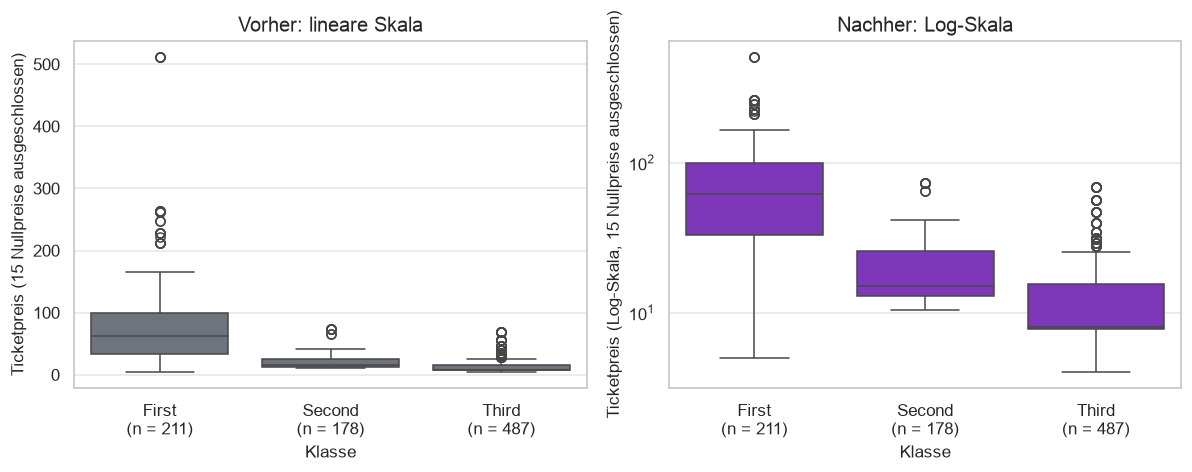

In [123]:
# Darstellen
n_je_klasse = titanic_pos.groupby('class', observed=True)['fare'].count()
beschriftung = [f'First\n(n = {n_je_klasse["First"]})',
                f'Second\n(n = {n_je_klasse["Second"]})',
                f'Third\n(n = {n_je_klasse["Third"]})']

fig, achsen = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, log_skala, titel, farbe in zip(
    achsen, [False, True],
    ['Vorher: lineare Skala', 'Nachher: Log-Skala'],
    ['#6B7280', '#7E22CE'],
):
    sns.boxplot(data=titanic_pos, x='class', y='fare', color=farbe, ax=ax)
    if log_skala:
        ax.set_yscale('log')
        ax.set_ylabel('Ticketpreis (Log-Skala, 15 Nullpreise ausgeschlossen)')
    else:
        ax.set_ylabel('Ticketpreis (15 Nullpreise ausgeschlossen)')
    ax.set(title=titel, xlabel='Klasse')
    ax.set_xticks(range(3), beschriftung)
plt.tight_layout()
plt.show()

**Bedeutung.** Links ist die halbe Grafik leer: Das Maximum von 512.33, das 35.4-Fache des Medians, bestimmt die Achse, und die Boxen der zweiten und dritten Klasse werden zu Strichen. Auf der Log-Skala werden die Mediane je Klasse (61.98, 15.02 und 8.05) und die Trennung der Klassen lesbar. Zwei Pflichten gehören dazu: Die Achse ist als Log-Skala gekennzeichnet, und der Ausschluss der 15 Nullpreise steht in der Beschriftung, samt n je Klasse. Wer stillschweigend Werte weglässt, berichtet einen anderen Datensatz.

> **Euer Datensatz.** Rechtfertigt das Verhältnis von Maximum zu Median bei eurer Variable eine Log-Skala? Enthält sie Nullen oder negative Werte, und was heisst das für den Logarithmus?

### 2.4 Box oder Violine?

**Problem.** Auf der Insel Biscoe zeigt der Boxplot der Flossenlängen eine unauffällige Box: Median 214 mm, IQR von 199.5 bis 220. Aus NB02 wisst ihr, dass auf Biscoe zwei Arten leben. Wo ist die Mischung im Boxplot geblieben?

**Theorie.** *Vorlesung: Folien «Violinplot: Idee und Lesen», «Box oder Violin?», «Violinplot und die Zipfel»*

Die Violine ist eine gespiegelte KDE je Gruppe: Die Breite ist proportional zur Dichte, mit `inner='quartile'` liegen die Quartile innen. Die Vorlesung stellt beide gegenüber: Die Box zeigt Median und IQR, robust und kompakt, verdeckt aber Mehrgipfligkeit; die Violine zeigt die ganze Form mit Moden und Tails, braucht dafür genug Daten. Und weil die KDE-Glocken über die echten Daten hinauslaufen, hat die Standard-Violine Zipfel jenseits von Minimum und Maximum; `cut=0` stoppt die Kurve an den beobachteten Werten.

**Code.** Erst die Artenmischung auf Biscoe und die Kennzahlen, dann dreimal dieselben Werte: als Box, als Violine mit Standard-Zipfeln und als Violine mit `cut=0`.

In [124]:
# Rechnen
print(pd.crosstab(penguins['island'], penguins['species']))

biscoe = penguins.loc[penguins['island'] == 'Biscoe', 'flipper_length_mm'].dropna()
q1_b, median_b, q3_b = biscoe.quantile([0.25, 0.50, 0.75])
print(f'\nBiscoe: n = {len(biscoe)}, Minimum {biscoe.min():.0f} mm, Maximum {biscoe.max():.0f} mm')
print(f'Median {median_b:.1f} mm, Quartile {q1_b:.1f} bis {q3_b:.1f} mm')
print(f'Boxhöhe = IQR = {q3_b - q1_b:.1f} mm; die SD wäre {biscoe.std(ddof=1):.1f} mm, '
      f'eine andere Zahl')

species    Adelie  Chinstrap  Gentoo
island                              
Biscoe         44          0     124
Dream          56         68       0
Torgersen      52          0       0

Biscoe: n = 167, Minimum 172 mm, Maximum 231 mm
Median 214.0 mm, Quartile 199.5 bis 220.0 mm
Boxhöhe = IQR = 20.5 mm; die SD wäre 14.1 mm, eine andere Zahl


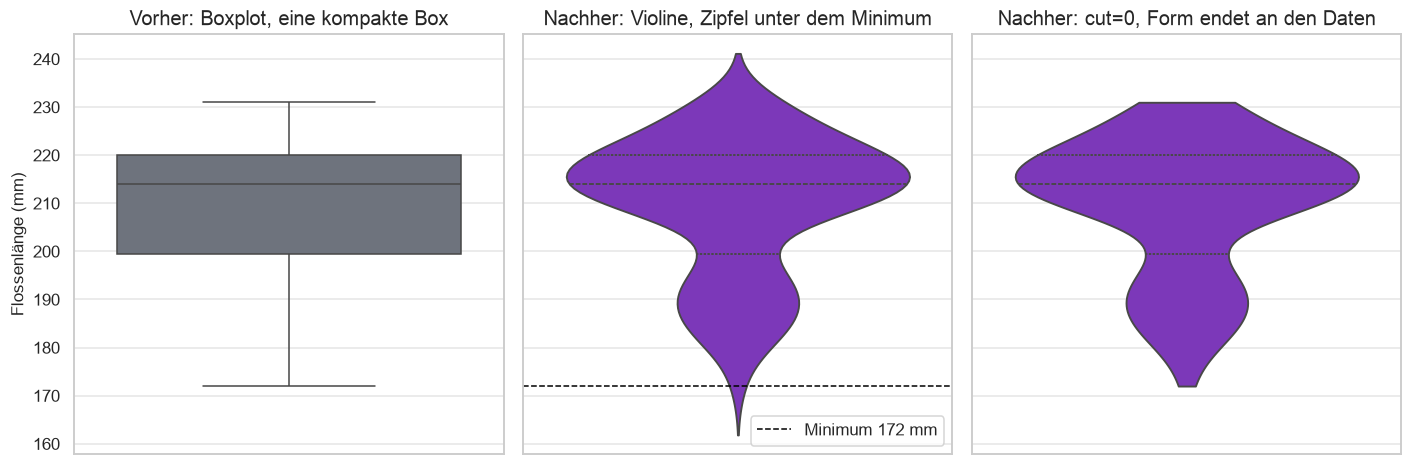

In [125]:
# Darstellen
fig, achsen = plt.subplots(1, 3, figsize=(13, 4.4), sharey=True)

sns.boxplot(y=biscoe, color='#6B7280', ax=achsen[0])
achsen[0].set(title='Vorher: Boxplot, eine kompakte Box', ylabel='Flossenlänge (mm)')

sns.violinplot(y=biscoe, color='#7E22CE', inner='quartile', ax=achsen[1])
achsen[1].axhline(biscoe.min(), color='black', linestyle='--', linewidth=1,
                  label=f'Minimum {biscoe.min():.0f} mm')
achsen[1].set(title='Nachher: Violine, Zipfel unter dem Minimum', ylabel='')
achsen[1].legend(loc='lower right')

sns.violinplot(y=biscoe, color='#7E22CE', inner='quartile', cut=0, ax=achsen[2])
achsen[2].set(title='Nachher: cut=0, Form endet an den Daten', ylabel='')
plt.tight_layout()
plt.show()

**Bedeutung.** Die Box komprimiert die 167 Messwerte auf fünf robuste Zahlen und verdeckt die Mischung der Arten vollständig (laut Crosstab 44 Adelie- und 124 Gentoo-Zeilen; ein Gentoo ohne Flossenlänge); die Violine zeigt sie als zwei Beulen um 189 und 216 mm. Die Boxhöhe ist dabei der IQR (20.5 mm), nicht die SD, eine der Fallen aus der Vorlesung. Die Zipfel der mittleren Violine deuten Flossen unter dem Minimum von 172 mm an, die es nicht gibt: Sie sind Schätzartefakte der KDE, für Berichte gehört `cut=0` dazu. Und die Violine erbt die Bandbreitenfrage aus Kapitel 1: Bei kleinen Gruppen lieber Boxplot plus Rohdatenpunkte statt einer glatten Dichte, die es nicht gibt.

> **Euer Datensatz.** Braucht euer wichtigster Gruppenvergleich die ganze Form (Violine) oder reichen Median und IQR (Box)? Wie klein ist eure kleinste Gruppe, und was heisst das für die Wahl?

> **Take-Home Box und Violin**
>
> 1. **Boxplot** = Median, IQR und Kandidaten; die Whisker enden am letzten beobachteten Wert, nicht bei Min/Max.
> 2. **`whis` ist eine Wahl:** Tukey markiert Kandidaten (0.7 Prozent auch bei Normaldaten), Perzentil-Whisker markieren immer; `showfliers=False` nur mit Hinweis.
> 3. **Notch** = Unsicherheitsbereich des Medians: Überlappung heisst nichts behaupten.
> 4. **Log-Skala** bei starker Rechtsschiefe, gekennzeichnet und mit dokumentiertem Umgang mit Nullen.
> 5. **Violine** zeigt Form und Moden (`inner='quartile'`, `cut=0`), braucht genug Daten; n je Gruppe angeben.
>
> Robuste Kennzahlen und Formdarstellung ergeben erst zusammen den vollen Überblick.

---

## 3. ECDF und QQ-Plot

*Vorlesung: Abschnitt «ECDF und QQ Plot». Leitfrage: Passt die Form zu einer Referenz, und wie notiert man die Entscheidung?*

Die ECDF und ihre zwei Leserichtungen kennt ihr aus NB02. Hier kommt der Gruppenvergleich dazu, und mit dem QQ-Plot das feinste Werkzeug dieses Kapitels: Datenquantile gegen eine Referenzverteilung, Punkt für Punkt.

### 3.1 ECDF im Gruppenvergleich

**Problem.** Die Adelie-Flossen erreichen die 50-Prozent-Marke bei 190 mm, die Gentoo-Flossen erst bei 216 mm. Im ECDF-Overlay liegt die Gentoo-Kurve trotzdem unten. Warum ist unten hier grösser?

**Theorie.** *Vorlesung: Folien «Wiederholung: ECDF Grundidee», «Wiederholung: ECDF Quantile», «ECDF: Gruppenvergleich»*

Die ECDF $\hat F(x) = \frac{1}{n} \sum_{i=1}^{n} \mathbb{1}\{x_i \le x\}$ kennt ihr aus NB02: binfrei, vollständig, jeder Wert zählt. Neu ist das Overlay mehrerer Gruppen: Eine Kurve, die tiefer verläuft, erreicht denselben Anteil erst bei höheren Werten, die Gruppe ist also nach rechts verschoben. Wo sich zwei Kurven kreuzen, unterscheiden sich nicht nur die Lagen, sondern die Formen.

**Code.** Kennzahlen je Art, dann der Vergleich: vorher drei getrennte Histogramme, nachher drei ECDFs auf einer Achse mit den Hilfslinien bei 0.5 und bei 200 mm.

In [126]:
# Rechnen
je_art = penguins.groupby('species')['flipper_length_mm']
tabelle = je_art.agg(['count', 'median'])
tabelle['P90'] = je_art.quantile(0.9)

for art in ['Adelie', 'Chinstrap', 'Gentoo']:
    werte_art = penguins.loc[penguins['species'] == art, 'flipper_length_mm'].dropna()
    tabelle.loc[art, 'Anteil <= 200 mm'] = (werte_art <= 200).mean()

tabelle.round(3)

,count,median,P90,Anteil <= 200 mm
species,,,,
Adelie,151,190.0,198.0,0.954
Chinstrap,68,196.0,205.0,0.735
Gentoo,123,216.0,228.0,0.000


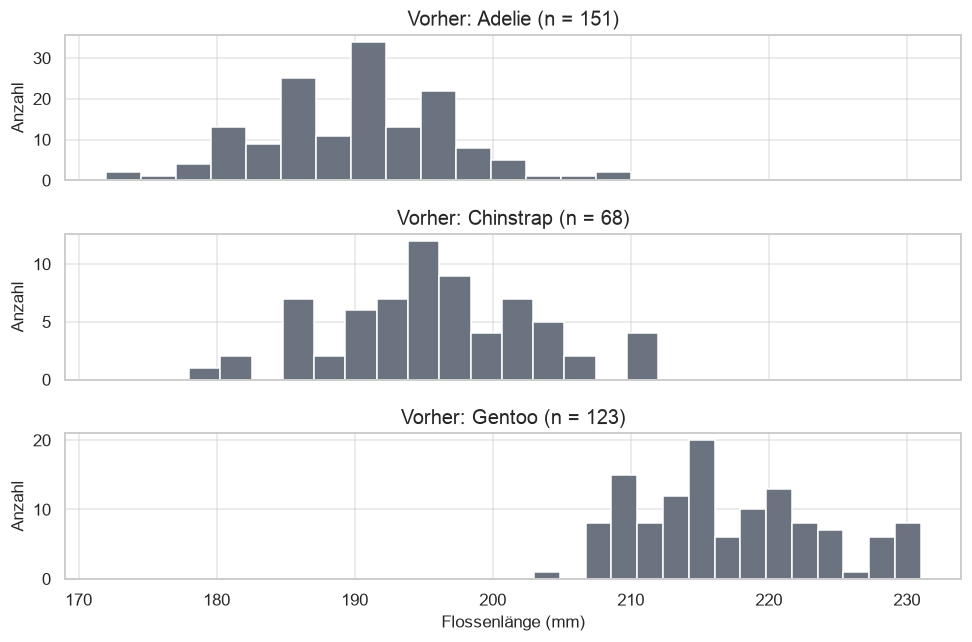

In [127]:
# Darstellen
arten = ['Adelie', 'Chinstrap', 'Gentoo']
fig, achsen = plt.subplots(3, 1, figsize=(9, 6), sharex=True)
for ax, art in zip(achsen, arten):
    werte_art = penguins.loc[penguins['species'] == art, 'flipper_length_mm'].dropna()
    ax.hist(werte_art, bins=15, color='#6B7280', edgecolor='white')
    ax.set(title=f'Vorher: {art} (n = {len(werte_art)})', ylabel='Anzahl')
achsen[-1].set_xlabel('Flossenlänge (mm)')
plt.tight_layout()
plt.show()

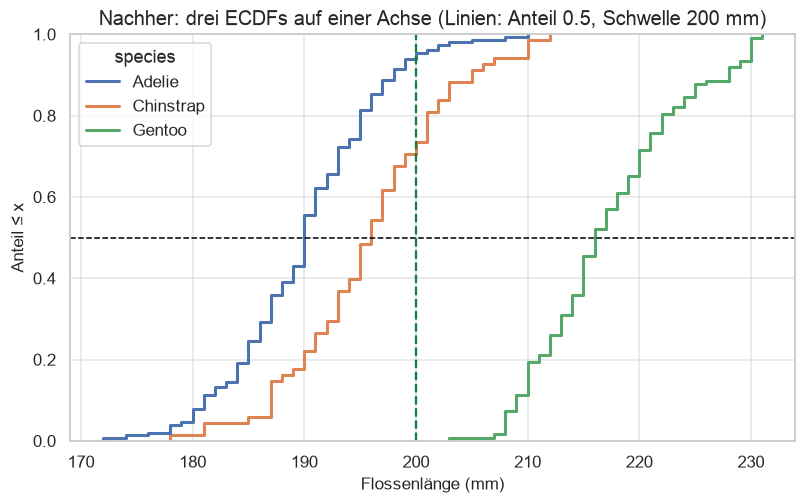

In [128]:
# Darstellen
fig, ax = plt.subplots(figsize=(8.5, 4.8))
sns.ecdfplot(data=penguins, x='flipper_length_mm', hue='species', linewidth=2, ax=ax)
ax.axhline(0.5, color='black', linestyle='--', linewidth=1)
ax.axvline(200, color='#15803D', linestyle='--', linewidth=1.5)
ax.set(title='Nachher: drei ECDFs auf einer Achse (Linien: Anteil 0.5, Schwelle 200 mm)',
       xlabel='Flossenlänge (mm)', ylabel='Anteil ≤ x')
plt.show()

**Bedeutung.** An der Schwelle 200 mm hat Adelie schon 95.4 Prozent der Werte eingesammelt, Chinstrap 73.5 Prozent, Gentoo 0: Die Gentoo-Kurve hinkt hinterher und verläuft deshalb unten, obwohl ihre Werte die grössten sind. Merksatz der Vorlesung: Unten heisst grösser. Die drei Kurven kreuzen sich hier nicht, die Arten unterscheiden sich also vor allem in der Lage. Gegenüber den drei Histogramm-Panels braucht das Overlay keine Bin-Entscheidung und nur eine Achse; deshalb ist die ECDF in der Diagnose-Routine von 3.4 der erste Plot.

> **Euer Datensatz.** Überlagert die ECDFs eurer Gruppen. Liegt eine Kurve durchgehend unter der anderen, oder kreuzen sie sich, und was heisst das für euren Vergleich?

### 3.2 QQ-Plot von Hand

**Problem.** Das Histogramm der 151 Adelie-Flossen sieht ungefähr symmetrisch aus; Mittelwert 189.95 mm und Median 190.0 mm liegen fast aufeinander. Reicht «sieht symmetrisch aus», oder lässt sich «mit einer Normalverteilung verträglich» prüfen, ohne ein neues Paket zu installieren?

**Theorie.** *Vorlesung: Folie «QQ-Plot: Grundidee»*

Ein QQ-Plot vergleicht Quantile: Jeder Punkt ist $(Q_p^{\mathrm{Ref}},\, Q_p^{\mathrm{Daten}})$ für denselben Anteil p, die Referenz ist meist die Normalverteilung. Liegen die Punkte auf einer Geraden, sind die Daten mit der Referenz verträglich; systematische Abweichungen zeigen Schiefe oder Tails. Für n sortierte Werte nimmt man die Anteile $p_i = (i - 0.5)/n$, damit weder 0 noch 1 erreicht wird.

**Code.** Ein QQ-Plot in wenigen Zeilen NumPy: sortieren, Anteile bilden, Normalquantile über eine grosse Referenzstichprobe bestimmen, Gerade robust durch die Q1/Q3-Punkte legen. Die Grafik zeigt das Histogramm (vorher) und den QQ-Plot (nachher).

In [129]:
# Rechnen
adelie = penguins.loc[penguins['species'] == 'Adelie', 'flipper_length_mm'].dropna()

daten = np.sort(adelie.to_numpy())                       # 1. sortieren
p = (np.arange(1, len(daten) + 1) - 0.5) / len(daten)    # 2. Anteile p_i = (i − 0.5) / n

# 3. Normalquantile ohne Zusatzpaket: Quantile einer grossen Standardnormal-Stichprobe.
#    Das kehrt die ECDF der Referenz um, genau wie in NB02 die Quantile der Daten.
rng_referenz = np.random.default_rng(SEED)
z_referenz = rng_referenz.standard_normal(1_000_000)
q_normal = np.quantile(z_referenz, p)

# 4. Referenzgerade robust durch die Q1/Q3-Punkte
q1_daten, q3_daten = np.quantile(daten, [0.25, 0.75])
q1_ref, q3_ref = np.quantile(z_referenz, [0.25, 0.75])
steigung = (q3_daten - q1_daten) / (q3_ref - q1_ref)
achsenabschnitt = q1_daten - steigung * q1_ref

print(f'n = {len(daten)}, Mittelwert {daten.mean():.2f} mm, Median {np.median(daten):.1f} mm')
print(f'Steigung der Q1/Q3-Geraden: {steigung:.2f} mm; zum Vergleich die SD: {adelie.std(ddof=1):.2f} mm')

n = 151, Mittelwert 189.95 mm, Median 190.0 mm
Steigung der Q1/Q3-Geraden: 6.68 mm; zum Vergleich die SD: 6.54 mm


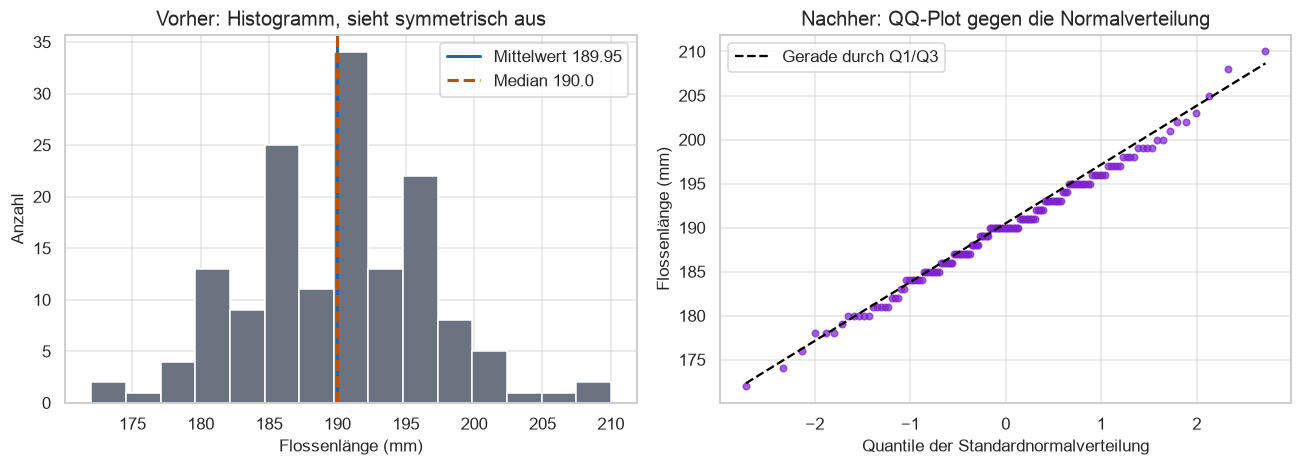

In [130]:
# Darstellen
fig, achsen = plt.subplots(1, 2, figsize=(12, 4.4))

achsen[0].hist(daten, bins=15, color='#6B7280', edgecolor='white')
achsen[0].axvline(daten.mean(), color='#2166AC', linewidth=2, label=f'Mittelwert {daten.mean():.2f}')
achsen[0].axvline(np.median(daten), color='#B45309', linewidth=2, linestyle='--',
                  label=f'Median {np.median(daten):.1f}')
achsen[0].set(title='Vorher: Histogramm, sieht symmetrisch aus',
              xlabel='Flossenlänge (mm)', ylabel='Anzahl')
achsen[0].legend(loc='upper right')

achsen[1].scatter(q_normal, daten, s=18, color='#7E22CE', alpha=0.7)
achsen[1].plot(q_normal, achsenabschnitt + steigung * q_normal, color='black',
               linestyle='--', linewidth=1.5, label='Gerade durch Q1/Q3')
achsen[1].set(title='Nachher: QQ-Plot gegen die Normalverteilung',
              xlabel='Quantile der Standardnormalverteilung', ylabel='Flossenlänge (mm)')
achsen[1].legend(loc='upper left')
plt.tight_layout()
plt.show()

**Bedeutung.** Die Punkte folgen der Geraden über den ganzen Bereich; nennenswerte Abweichungen gibt es höchstens an den äussersten Enden, wo einzelne Werte immer streuen. Die Adelie-Flossen sind also mit einer Normalverteilung verträglich. Das ist keine bewiesene Normalität, sondern kein Widerspruch bei n = 151, und genau solche Verträglichkeit setzen Verfahren ab VL06 voraus. Nebenbefund: Die Steigung der Q1/Q3-Geraden (6.68 mm) ist eine robuste Schätzung der SD (6.54 mm). Und das Wichtigste für euer Projekt: Der ganze Plot ist eine Handvoll Zeilen NumPy.

> **Euer Datensatz.** Baut den QQ-Plot für eure zentrale metrische Variable nach. Verlassen die Punkte die Gerade, und wenn ja: an den Enden oder in der Mitte?

### 3.3 Bogen oder S-Kurve?

**Problem.** Die Ticketpreise (Mittelwert 32.20, Median 14.45) und eine simulierte Messreihe mit bekannter Wahrheit haben beide extreme Werte, und beide Histogramme sehen «auffällig» aus. Der QQ-Plot trennt, was das Histogramm vermischt: Schiefe oder schwere Tails?

**Theorie.** *Vorlesung: Folie «Normal-QQ: Lesen»*

Zwei Muster mit Namen. Ein **Bogen** zeigt Schiefe: Liegen beide Enden über der Geraden, sind die Daten rechtsschief; liegen beide darunter, linksschief. Eine **S-Kurve** zeigt schwere Tails: links unten unter der Geraden, rechts oben darüber, in beiden Extremen also mehr, als die Normalverteilung erwarten lässt. Und immer gilt: das Muster mit Histogramm oder ECDF abgleichen.

**Code.** Reihe 1 sind die Ticketpreise. Reihe 2 ist eine symmetrische Verteilung mit schweren Tails (Student-t mit df=3), simuliert mit bekannter Wahrheit. Danach dieselben QQ-Zeilen wie in 3.2, einmal je Reihe. Die Grafik stellt oben die Histogramme, unten die QQ-Plots gegenüber.

In [131]:
# Rechnen
rng_tails = np.random.default_rng(SEED)
symmetrisch_heavy = rng_tails.standard_t(df=3, size=2000)

print(f'Ticketpreise: Mittelwert {fare.mean():.2f}, Median {fare.median():.2f}  ->  schief')
print(f'Simulation:   Mittelwert {symmetrisch_heavy.mean():.3f}, '
      f'Median {np.median(symmetrisch_heavy):.3f}  ->  symmetrisch um 0')
print(f'Extreme der Simulation: Minimum {symmetrisch_heavy.min():.1f}, '
      f'Maximum {symmetrisch_heavy.max():.1f}; bei einer Normalverteilung wären Werte '
      f'jenseits von ±4 auch bei n = 2000 kaum je zu sehen')

Ticketpreise: Mittelwert 32.20, Median 14.45  ->  schief
Simulation:   Mittelwert -0.009, Median 0.034  ->  symmetrisch um 0
Extreme der Simulation: Minimum -9.1, Maximum 13.9; bei einer Normalverteilung wären Werte jenseits von ±4 auch bei n = 2000 kaum je zu sehen


In [132]:
# Rechnen
# Dieselben Zeilen wie in 3.2, einmal für die Ticketpreise ...
preise_sortiert = np.sort(fare.to_numpy())
p_preise = (np.arange(1, len(preise_sortiert) + 1) - 0.5) / len(preise_sortiert)
q_normal_preise = np.quantile(z_referenz, p_preise)
q1_p, q3_p = np.quantile(preise_sortiert, [0.25, 0.75])
steigung_preise = (q3_p - q1_p) / (q3_ref - q1_ref)
abschnitt_preise = q1_p - steigung_preise * q1_ref

# ... und einmal für die Simulation (bewusst wiederholt statt Funktion: das ist das Muster)
sim_sortiert = np.sort(symmetrisch_heavy)
p_sim = (np.arange(1, len(sim_sortiert) + 1) - 0.5) / len(sim_sortiert)
q_normal_sim = np.quantile(z_referenz, p_sim)
q1_s, q3_s = np.quantile(sim_sortiert, [0.25, 0.75])
steigung_sim = (q3_s - q1_s) / (q3_ref - q1_ref)
abschnitt_sim = q1_s - steigung_sim * q1_ref

print('QQ-Koordinaten für beide Reihen berechnet.')

QQ-Koordinaten für beide Reihen berechnet.


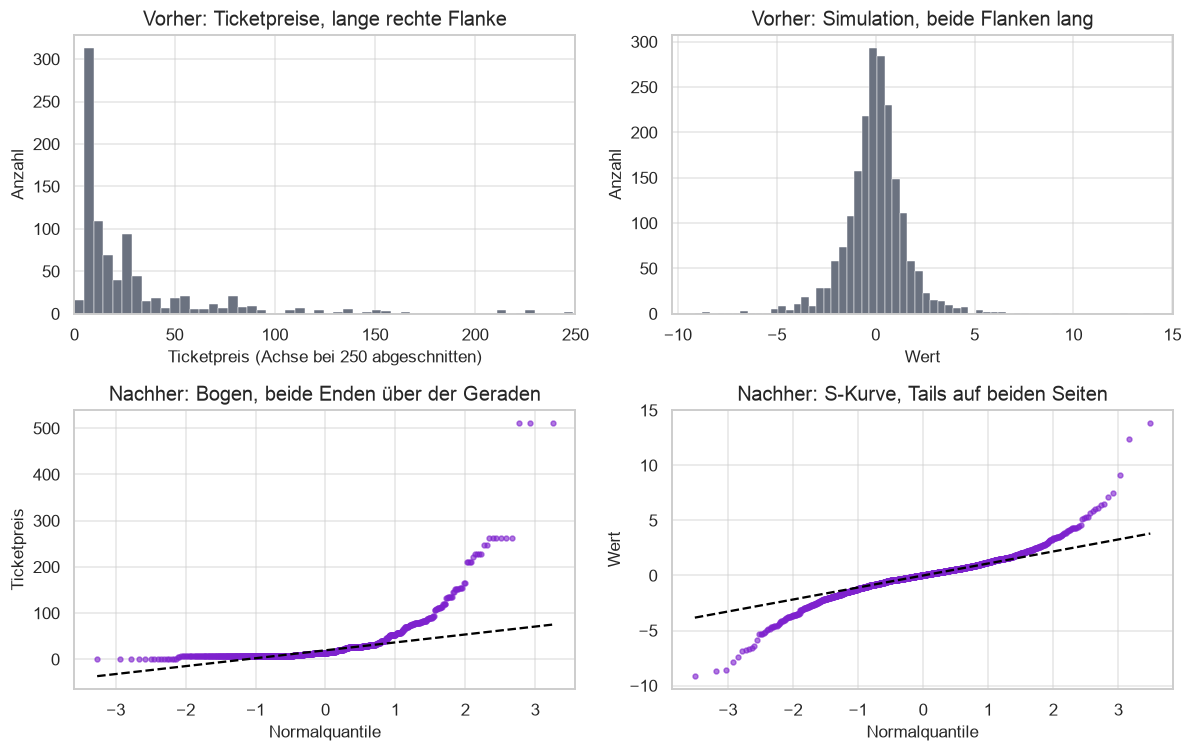

In [133]:
# Darstellen
fig, achsen = plt.subplots(2, 2, figsize=(11, 7))

achsen[0, 0].hist(fare, bins=kanten_fd, color='#6B7280', edgecolor='white', linewidth=0.3)
achsen[0, 0].set(title='Vorher: Ticketpreise, lange rechte Flanke', xlim=(0, 250),
                 xlabel='Ticketpreis (Achse bei 250 abgeschnitten)', ylabel='Anzahl')

achsen[0, 1].hist(symmetrisch_heavy, bins=60, color='#6B7280', edgecolor='white', linewidth=0.3)
achsen[0, 1].set(title='Vorher: Simulation, beide Flanken lang', xlabel='Wert', ylabel='Anzahl')

achsen[1, 0].scatter(q_normal_preise, preise_sortiert, s=10, color='#7E22CE', alpha=0.6)
achsen[1, 0].plot(q_normal_preise, abschnitt_preise + steigung_preise * q_normal_preise,
                  color='black', linestyle='--', linewidth=1.5)
achsen[1, 0].set(title='Nachher: Bogen, beide Enden über der Geraden',
                 xlabel='Normalquantile', ylabel='Ticketpreis')

achsen[1, 1].scatter(q_normal_sim, sim_sortiert, s=10, color='#7E22CE', alpha=0.6)
achsen[1, 1].plot(q_normal_sim, abschnitt_sim + steigung_sim * q_normal_sim,
                  color='black', linestyle='--', linewidth=1.5)
achsen[1, 1].set(title='Nachher: S-Kurve, Tails auf beiden Seiten',
                 xlabel='Normalquantile', ylabel='Wert')
plt.tight_layout()
plt.show()

**Bedeutung.** Der QQ-Plot der Ticketpreise verlässt die Gerade an beiden Enden nach oben: ein Bogen, also Rechtsschiefe, konsistent mit dem Mittelwert weit über dem Median. Die Simulation liegt links unter und rechts über der Geraden: eine S-Kurve, schwere Tails bei fast perfekter Symmetrie von Mittelwert und Median. Damit ist der Satz aus NB02 eingelöst: Heavy-tailed bedeutet nicht automatisch rechtsschief. Dort konnte er nur behauptet werden, der QQ-Plot zeigt ihn. Die Konsequenz bleibt dieselbe: robuste Kennzahlen berichten, und markierte Punkte sind Verteilungsenden, keine Löschaufträge.

> **Euer Datensatz.** Zeigt euer QQ-Plot einen Bogen oder eine S-Kurve? Welche Kennzahlen aus NB02 folgen aus dem Muster?

### 3.4 Die Diagnose-Routine

**Problem.** Zurück zur API-Latenzreihe aus NB02: 500 Messungen, simuliert mit bekannter Wahrheit. Der naive Berichtssatz wäre: «Durchschnittliche Antwortzeit 16.46 ms.» Die Routine der Vorlesung prüft in vier Schritten, ob dieser Satz trägt, und endet mit einem notierten Entscheid.

**Theorie.** *Vorlesung: Folie «Kombinierte Diagnostik»*

Kein Plot allein reicht; die Diagnose entsteht aus der Kombination, in fester Reihenfolge: erst Kennzahlen und ECDF, dann Histogramm mit KDE, dann QQ-Plot. Danach die Konsistenz prüfen: Sagen alle Werkzeuge dasselbe? Und zum Schluss die Entscheidung kurz notieren, mit den gewählten Parametern.

**Code.** Die Latenzreihe wird mit demselben Seed wie in NB02 exakt reproduziert. Vorher steht der Kennzahlen-Print, nachher das Diagnosebild mit den drei Plots in Routinen-Reihenfolge.

In [134]:
# Rechnen
rng_latenz = np.random.default_rng(7)      # derselbe Seed wie in NB02, erste Ziehung
latenz = pd.Series(rng_latenz.lognormal(mean=2.7, sigma=0.65, size=500), name='Latenz (ms)')

q1_l, median_l, q3_l = latenz.quantile([0.25, 0.50, 0.75])
p90_l = latenz.quantile(0.90)
oberer_zaun_l = q3_l + 1.5 * (q3_l - q1_l)

print(f'n = {len(latenz)}')
print(f'Median {median_l:.2f} ms, Mittelwert {latenz.mean():.2f} ms')
print(f'Q1 {q1_l:.2f} ms, Q3 {q3_l:.2f} ms, SD {latenz.std(ddof=1):.2f} ms')
print(f'P90 {p90_l:.2f} ms')
print(f'Über dem oberen Tukey-Zaun ({oberer_zaun_l:.2f} ms): {(latenz > oberer_zaun_l).sum()} Werte')

n = 500
Median 13.95 ms, Mittelwert 16.46 ms
Q1 8.88 ms, Q3 20.75 ms, SD 10.73 ms
P90 30.13 ms
Über dem oberen Tukey-Zaun (38.56 ms): 25 Werte


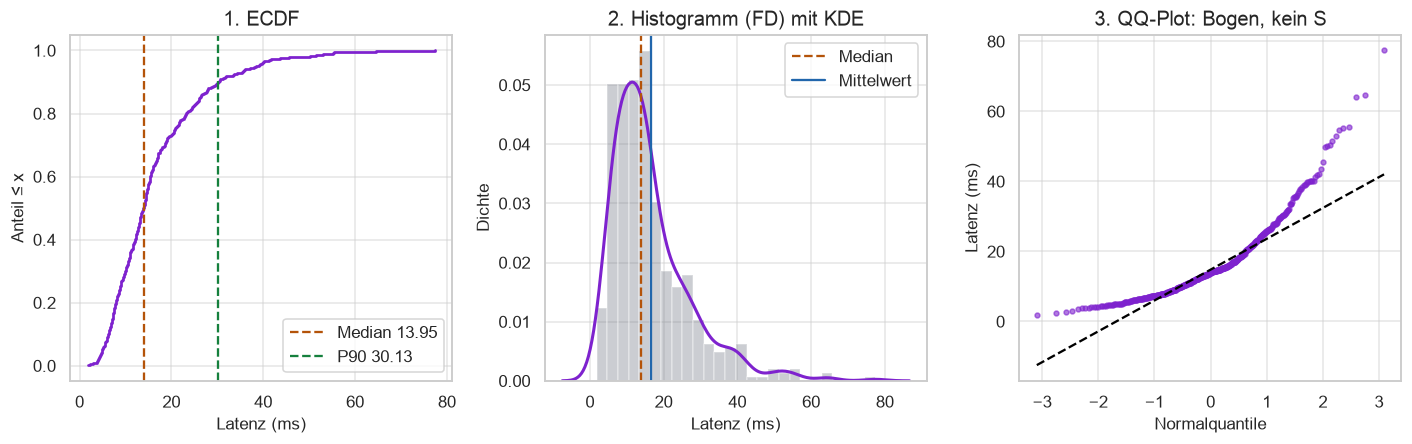

In [135]:
# Darstellen
latenz_sortiert = np.sort(latenz.to_numpy())
anteil_latenz = np.arange(1, len(latenz_sortiert) + 1) / len(latenz_sortiert)       # ECDF: i/n
p_latenz = (np.arange(1, len(latenz_sortiert) + 1) - 0.5) / len(latenz_sortiert)    # QQ: (i − 0.5)/n
q_normal_latenz = np.quantile(z_referenz, p_latenz)
q1_ld, q3_ld = np.quantile(latenz_sortiert, [0.25, 0.75])
steigung_latenz = (q3_ld - q1_ld) / (q3_ref - q1_ref)
abschnitt_latenz = q1_ld - steigung_latenz * q1_ref

kanten_latenz = np.histogram_bin_edges(latenz, bins='fd')

fig, achsen = plt.subplots(1, 3, figsize=(13, 4.2))

# 1. ECDF mit Median und P90
achsen[0].step(latenz_sortiert, anteil_latenz, where='post', color='#7E22CE', linewidth=1.8)
achsen[0].axvline(median_l, color='#B45309', linestyle='--', linewidth=1.5,
                  label=f'Median {median_l:.2f}')
achsen[0].axvline(p90_l, color='#15803D', linestyle='--', linewidth=1.5, label=f'P90 {p90_l:.2f}')
achsen[0].set(title='1. ECDF', xlabel='Latenz (ms)', ylabel='Anteil ≤ x')
achsen[0].legend(loc='lower right')

# 2. FD-Histogramm mit KDE
achsen[1].hist(latenz, bins=kanten_latenz, density=True,
               color='#6B7280', alpha=0.35, edgecolor='white')
sns.kdeplot(latenz, bw_adjust=1.0, color='#7E22CE', linewidth=2, ax=achsen[1])
achsen[1].axvline(median_l, color='#B45309', linestyle='--', linewidth=1.5, label='Median')
achsen[1].axvline(latenz.mean(), color='#2166AC', linewidth=1.5, label='Mittelwert')
achsen[1].set(title='2. Histogramm (FD) mit KDE', xlabel='Latenz (ms)', ylabel='Dichte')
achsen[1].legend(loc='upper right')

# 3. QQ gegen die Normalverteilung
achsen[2].scatter(q_normal_latenz, latenz_sortiert, s=10, color='#7E22CE', alpha=0.6)
achsen[2].plot(q_normal_latenz, abschnitt_latenz + steigung_latenz * q_normal_latenz,
               color='black', linestyle='--', linewidth=1.5)
achsen[2].set(title='3. QQ-Plot: Bogen, kein S', xlabel='Normalquantile', ylabel='Latenz (ms)')
plt.tight_layout()
plt.show()

**Bedeutung.** Alle drei Werkzeuge sagen dasselbe: Die ECDF steigt unten steil und zieht sich oben lang hin, Histogramm und KDE zeigen eine rechtsschiefe, unimodale Form, und der QQ-Plot ist ein Bogen, kein S. Die Diagnose ist konsistent, also folgt der Entscheid, ein Satz für das Log: «Die Latenz ist rechtsschief mit schwerem rechtem Tail (QQ-Bogen); wir berichten Median 13.95 ms mit IQR 8.88 bis 20.75 ms und P90 30.13 ms als Servicegrenze; die 25 Tukey-Kandidaten gehören zur Flanke und werden nicht gelöscht (Parameter: FD-Bins, bw_adjust 1.0, whis 1.5).» Der naive Mittelwert von 16.46 ms hätte den typischen Fall um fast 20 Prozent überzeichnet.

> **Euer Datensatz.** Lauft die Routine einmal vollständig für eure zentrale Variable und schreibt genau einen solchen Entscheidungssatz mit allen Parametern ins Log. Welche der vier Stationen hat eure Meinung geändert?

> **Take-Home ECDF und QQ**
>
> 1. **ECDF**: binfrei und vollständig; Quantile direkt ablesbar, auch bei kleinem n.
> 2. **Gruppen im Overlay**: Unten heisst grösser; Kreuzungen zeigen Formunterschiede.
> 3. **QQ-Plot**: Gerade = verträglich, Bogen = Schiefe, S-Kurve = schwere Tails.
> 4. **Routine**: Kennzahlen und ECDF, Histogramm mit KDE, QQ, Konsistenz, notierter Entscheid.
>
> ECDF für den Überblick, QQ für die Feindiagnose, die Kombination für die Entscheidung.

---

## 4. Zusammenfassung und Übertragung

Die drei Lernziele der Vorlesung, jeweils mit der Stelle, an der sie im Notebook laufen:

| # | Lernziel | Abschnitt |
|---|---|---|
| 01 | **Form zeigen**: Histogramm und KDE mit begründeter Binzahl und Bandbreite lesen | 1 |
| 02 | **Gruppen vergleichen**: Boxplot, Violinplot und Rohdatenpunkte ohne Überinterpretation | 2 |
| 03 | **Form prüfen**: ECDF und QQ-Plot kombinieren und die Entscheidung dokumentieren | 3 |

Die wichtigsten drei Sätze des Notebooks:

1. **Die Darstellung ist nicht die Wahrheit.** Bins und Bandbreite steuern die Aussage; echt ist, was mehrere sinnvolle Einstellungen übersteht.
2. **Ein Boxplot markiert nach einer Regel, die ihr gewählt habt.** `whis`, `showfliers` und die Skala gehören deshalb in den Bericht, samt n je Gruppe.
3. **Keine Diagnose aus einem einzelnen Plot.** ECDF, Histogramm mit KDE und QQ-Plot zusammen, dann die Entscheidung in einem Satz ins Log.

### Was ihr mit eurem eigenen Datensatz macht

Die Fragen **Euer Datensatz** in den Abschnitten 1 bis 3 führen durch diese Schritte.

**1. Variable und Gruppen festlegen.** Führt die metrische Variable aus NB02 weiter. Nennt n, die fehlenden Werte und die kleinste Gruppengrösse.

**2. Die Form zeigen.** Rechnet die FD-Klassenzahl, zeichnet das Overlay aus Histogramm und KDE und prüft `bw_adjust` mit 0.5, 1.0 und 2.0. Notiert, was stabil bleibt; Bins und Bandbreite gehören in den Bericht.

**3. Gruppen robust vergleichen.** Boxplot je Gruppe mit begründetem `whis` und dokumentiertem `showfliers`. Bei starker Rechtsschiefe prüft die Log-Skala, kennzeichnet sie und dokumentiert den Umgang mit Nullen.

**4. Die Form je Gruppe prüfen.** Violine mit Quartilen und `cut=0`, bei kleinen Gruppen Boxplot plus Punkte. Seht die Kerben-Überlappung an, bevor ihr einen Lageunterschied behauptet.

**5. Das ECDF-Overlay lesen.** Dominanz oder Kreuzung? Lest relevante Schwellen wie P90 oder Servicegrenzen direkt ab.

**6. QQ gegen die Normalverteilung.** Übertragt das Muster aus 3.2. Benennt Bogen oder S-Kurve und leitet daraus die Kennzahlwahl ab.

**7. Die Routine einmal vollständig.** Schreibt den Entscheidungssatz mit allen Parametern (Bins, Bandbreite, whis, Skala) ins Entscheidungs-Log. Er gehört in jeden Bericht über eure Variable. Für auffällige Einzelfälle ergänzt eine Fallnotiz nach dem Muster im Begleitnotebook `NB03_Ausreisserregeln.ipynb`.

**Was VL03 bewusst noch nicht beantwortet.** Ob ein sichtbarer Unterschied statistisch belastbar ist, klären erst Konfidenzintervalle und Tests (Woche 06 bis 08); deshalb bleibt die Kerbe hier ein Unsicherheitsbereich ohne Formel. Formale Normalitätstests ersetzen den QQ-Plot nicht und folgen ebenfalls später. Zusammenhänge zwischen zwei Variablen sind das Thema von VL04. Und keine Grafik entscheidet, ob ein markierter Wert ein Fehler ist: Das bleibt fachliche Prüfung mit Dokumentation.

---

**Weiter in VL04:** Zusammenhänge zwischen zwei Variablen, also Kovarianz, Pearsons r, Spearmans rho und Kendalls tau, dazu das Simpson-Paradox und der Unterschied zwischen Korrelation und Kausalität.